<a href="https://colab.research.google.com/github/mardocheeogecime-gif/Rede_Colabora-o_Acad-mica_ECI_UFMG/blob/main/LAB_JOI_99_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB JOI · Paired method decisions and multiplicity-calibrated composites

## Setup: distinct JOI methodological problem

In [ ]:
%pip -q install pandas numpy pyarrow scipy matplotlib statsmodels
from pathlib import Path
import json, hashlib, platform, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from google.colab import drive
if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
ROOT=Path('/content/drive/MyDrive/CAPES_Epistemic_Change')
P94=ROOT/'94B_LAB04_JDIS_FULL_2013_2024_COMPUTATIONAL_REPLICATION_V1'
P95=ROOT/'95_LAB04_JDIS_THREE_TEST_DISTRIBUTIONAL_BENCHMARK_V1'
P96=ROOT/'96_LAB04_JDIS_REAL_DOCUMENT_SHAPE_BENCHMARK_V1'
P97=ROOT/'97_LAB04_JDIS_INFERENTIAL_SYNTHESIS_V1'
PANEL=ROOT/'78_LAB03_RESEARCH_POLICY_INSTITUTIONAL_PATH_DEPENDENCE_V1/01_LAB03_CERTIFIED_PANEL.parquet'
SELECT=P94/'03_PRIVATE_SELECTED_PPG_PAIRS.csv'
for p in [P94,P95,P96,P97,PANEL,SELECT]: assert p.exists(),f'STOP missing frozen input: {p}'
sel=pd.read_csv(SELECT,dtype={'ppg':'string','pair_id':'string','phase':'string','size_band':'string'})
sel['ppg']=sel.ppg.str.strip();sel['year']=pd.to_numeric(sel.year).astype(int)
assert len(sel)==352 and sel.pair_id.is_unique
FROZEN_SELECTION_SHA='4135aefe93595cb004c7912c02a7ce775c877f5f6b9e3a95d5c63bddb8be15c7'
assert hashlib.sha256(SELECT.read_bytes()).hexdigest()==FROZEN_SELECTION_SHA,'STOP changed selection'
panel=pd.read_parquet(PANEL,columns=['ppg','year','matched','n_docs','area','area_group','is_public','is_professional'])
assert len(panel)==51901 and int(panel.loc[panel.matched.fillna(False),'n_docs'].sum())==993086
panel.ppg=panel.ppg.astype('string').str.strip();panel.year=pd.to_numeric(panel.year).astype(int)
assert not panel[['ppg','year']].duplicated().any()
print('PASS 352 selected pairs; 51,901 programme-year observations; 993,086 titles')

OUT=ROOT/'99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1';OUT.mkdir(parents=True,exist_ok=True)
CFG={'version':'99JOI.v1','seed':991026,'bootstrap':1000,'alpha':0.05,'frozen_stage':'96','combine_rule':'Bonferroni minimum p-value of centroid and RBF-MMD','no_new_embedding':True,'posthoc_analysis':True}
HASH=hashlib.sha256(json.dumps(CFG,sort_keys=True).encode()).hexdigest()
(OUT/'00_CONFIG.json').write_text(json.dumps({'config':CFG,'sha256':HASH},indent=2))
print('JOI config',HASH)

Mounted at /content/drive
PASS 352 selected pairs; 51,901 programme-year observations; 993,086 titles
JOI config afc22bb2510576e5e23ac25e93bd141cf71d0453114280c76d1a22ab284cb143


## Recover raw matched p-values and independent replicate keys

In [ ]:
q=P96/'05_PRIVATE_ALL_METHOD_RESULTS.parquet'; assert q.is_file()
df=pd.read_parquet(q)
print('Columns:',list(df.columns));display(df.head(3))
REQ={'model','phase','year','ppg','pair_id','size_band','scenario','intensity','rep','method','p_mc'}
assert REQ.issubset(df),f'STOP required fields absent: {REQ-set(df)}'
assert not df[list(REQ-{'p_mc'})].duplicated().any(),'STOP duplicated raw p observations'
assert pd.to_numeric(df.p_mc,errors='coerce').between(0,1).all()
assert set(df.method)=={'centroid_cosine','energy_biased','rbf_mmd_biased'}
# Each experiment repetition is the matching unit for the statistical comparison.
KEY=['model','phase','year','ppg','pair_id','size_band','scenario','intensity','rep']
wide=df.pivot(index=KEY,columns='method',values='p_mc').reset_index()
assert wide[['centroid_cosine','energy_biased','rbf_mmd_biased']].notna().all().all()
assert len(wide)*3==len(df)
print('Paired scenario-replicates',len(wide),'raw tests',len(df))

Columns: ['model', 'phase', 'year', 'ppg', 'pair_id', 'size_band', 'scenario', 'intensity', 'rep', 'n_a', 'n_b', 'donor_ppg', 'n_replaced', 'centroid_distance', 'dispersion_A', 'dispersion_B', 'dispersion_difference', 'method', 'statistic', 'p_mc', 'rejected', 'null_mean', 'null_sd', 'excess', 'seconds_method']


,model,phase,year,ppg,pair_id,size_band,scenario,intensity,rep,n_a,...,dispersion_B,dispersion_difference,method,statistic,p_mc,rejected,null_mean,null_sd,excess,seconds_method
0,M1,DEVELOPMENT_2014_2019,2014,12002011012P9,P2014_3a0d0b034d54c355,11-20,observed,0.0,0,12,...,0.099609,-0.005822,centroid_cosine,0.013315,0.06,0,0.010418,0.001636,0.002897,0.030836
1,M1,DEVELOPMENT_2014_2019,2014,12002011012P9,P2014_3a0d0b034d54c355,11-20,observed,0.0,0,12,...,0.099609,-0.005822,rbf_mmd_biased,0.121501,0.07,0,0.104046,0.010011,0.017454,0.028527
2,M1,DEVELOPMENT_2014_2019,2014,12002011012P9,P2014_3a0d0b034d54c355,11-20,observed,0.0,0,12,...,0.099609,-0.005822,energy_biased,0.089894,0.07,0,0.078720,0.006350,0.011175,0.033111


Paired scenario-replicates 8448 raw tests 25344


## Established composite rules and exact paired metrics

In [ ]:
# Bonferroni min-p is an established multiplicity correction, NOT a novel theoretical test.
a=CFG['alpha'];wide['centroid_reject']=(wide.centroid_cosine<=a).astype(int)
wide['energy_reject']=(wide.energy_biased<=a).astype(int)
wide['mmd_reject']=(wide.rbf_mmd_biased<=a).astype(int)
wide['bonf_centroid_mmd_p']=np.minimum(1.,2*np.minimum(wide.centroid_cosine,wide.rbf_mmd_biased))
wide['bonf_centroid_energy_p']=np.minimum(1.,2*np.minimum(wide.centroid_cosine,wide.energy_biased))
wide['bonf_cm_reject']=(wide.bonf_centroid_mmd_p<=a).astype(int)
wide['bonf_ce_reject']=(wide.bonf_centroid_energy_p<=a).astype(int)
# These combinations control familywise error under valid marginal p-values, no independence assumption needed.
assert (wide[['bonf_centroid_mmd_p','bonf_centroid_energy_p']].to_numpy()>=0).all()
wide.to_parquet(OUT/'01_JOI_RAW_PAIRED_COMPOSITES_PRIVATE.parquet',index=False)
print('Composite rules computed without embedding recomputation')

Composite rules computed without embedding recomputation


## Within pair aggregation and clustered calibration/power

In [ ]:
def cluster_boot_mean(data,by='ppg',value='outcome',B=1000,seed=0):
    g=data.groupby(by,dropna=False)[value].agg(['sum','count'])
    if len(g)<8:return (np.nan,np.nan,int(len(g)))
    a=g['sum'].to_numpy(float);n=g['count'].to_numpy(float)
    rng=np.random.default_rng(seed); vals=np.empty(B)
    for k in range(B):
        ix=rng.integers(len(a),size=len(a)); vals[k]=a[ix].sum()/n[ix].sum()
    return (float(np.quantile(vals,.025)),float(np.quantile(vals,.975)),len(g))
def save_chart(fig,name):
    fig.tight_layout();fig.savefig(OUT/name,dpi=180,bbox_inches='tight');plt.close(fig)

methods={'centroid':'centroid_reject','energy':'energy_reject','mmd':'mmd_reject','bonf_centroid_mmd':'bonf_cm_reject','bonf_centroid_energy':'bonf_ce_reject'}
unit_cols=['model','phase','year','ppg','pair_id','size_band','scenario','intensity']
rep=wide.groupby(unit_cols,as_index=False)[list(methods.values())].mean()
rep.to_parquet(OUT/'02_JOI_PAIR_METHOD_PANEL.parquet',index=False)
rec=[]
for (model,phase,scenario,intensity),g in rep.groupby(['model','phase','scenario','intensity']):
 for label,col in methods.items():
  lo,hi,n=cluster_boot_mean(g,value=col,B=CFG['bootstrap'],seed=CFG['seed']+len(rec))
  rec.append({'model':model,'phase':phase,'scenario':scenario,'intensity':intensity,'method':label,'n_pairs':len(g),'n_ppg':n,'detection':g[col].mean(),'low95':lo,'high95':hi})
rates=pd.DataFrame(rec);rates.to_csv(OUT/'03_JOI_CALIBRATION_POWER_CLUSTER_CI.csv',index=False)
print('Calibration/power strata',len(rates))

Calibration/power strata 300


## Exact McNemar and cluster paired gains

In [ ]:
from scipy.stats import binomtest
comps={'energy':'energy_reject','mmd':'mmd_reject','bonf_cm':'bonf_cm_reject','bonf_ce':'bonf_ce_reject'}
rows=[]
for (model,phase,scenario,intensity),g in rep.groupby(['model','phase','scenario','intensity']):
 for name,col in comps.items():
  x=(g[col]-g.centroid_reject).astype(float)
  lo,hi,n=cluster_boot_mean(g.assign(diff=x),value='diff',B=CFG['bootstrap'],seed=CFG['seed']+len(rows))
  # McNemar exact appropriate only for BINARY single-replicate scenarios; negative replicates are fractional.
  valid=(g[col].isin([0.,1.]) & g.centroid_reject.isin([0.,1.])).all()
  b=int(((g[col]==1)&(g.centroid_reject==0)).sum()) if valid else -1
  c=int(((g[col]==0)&(g.centroid_reject==1)).sum()) if valid else -1
  pm=float(binomtest(b,b+c,.5).pvalue) if valid and b+c else (1. if valid else np.nan)
  rows.append({'model':model,'phase':phase,'scenario':scenario,'intensity':intensity,'method':name,'n_pairs':len(g),'n_ppg':n,'gain_vs_centroid':x.mean(),'low95':lo,'high95':hi,'discordant_b':b,'discordant_c':c,'mcnemar_exact_p_unadjusted':pm,'mcnemar_applicable':valid})
gain=pd.DataFrame(rows);gain.to_csv(OUT/'04_JOI_PAIRED_GAINS_AND_EXACT_TESTS.csv',index=False)
print('Paired comparisons',len(gain),'no claim of familywise significance across all cells')

Paired comparisons 240 no claim of familywise significance across all cells


## Multiple comparison control and method-mismatch diagnosis

In [ ]:
from statsmodels.stats.multitest import multipletests
v=gain.mcnemar_exact_p_unadjusted.notna()
gain['BH_q_exploratory']=np.nan
if v.any():gain.loc[v,'BH_q_exploratory']=multipletests(gain.loc[v,'mcnemar_exact_p_unadjusted'],method='fdr_bh')[1]
gain.to_csv(OUT/'04_JOI_PAIRED_GAINS_AND_EXACT_TESTS.csv',index=False)
# Simpson-type artifacts: negative control rejections counted after averaging, not as independent tests.
g=wide[wide.scenario=='negative'].copy()
cal=[]
for (model,phase),z in g.groupby(['model','phase']):
 for label,col in methods.items():
  cal.append({'model':model,'phase':phase,'method':label,'n_replicates':len(z),'nominal_alpha':CFG['alpha'],'empirical_rejection':z[col].mean(),'unique_ppg':z.ppg.nunique()})
pd.DataFrame(cal).to_csv(OUT/'05_JOI_RAW_REPLICATE_NULL_CALIBRATION.csv',index=False)

## Geometry-conditional gain and method-selection risks

In [ ]:
# Geometric diagnostics are from actual vectors, not from labels generated for validation.
geometry=wide.groupby(['model','phase','scenario','pair_id'],as_index=False).agg(n=('rep','size'))
raw=df[df.method=='centroid_cosine'].copy()
for candidate in ['centroid_distance','dispersion_difference']:
 if candidate in raw.columns:
  zz=raw.groupby(['model','phase','scenario','pair_id'],as_index=False)[candidate].mean()
  geometry=geometry.merge(zz,on=['model','phase','scenario','pair_id'],validate='one_to_one')
geometry.to_csv(OUT/'06_JOI_GEOMETRY_METADATA.csv',index=False)
# Report classification of opportunities, not algorithmic optimization on exposed replication phases.
if 'centroid_distance' in geometry:
 a=rep.merge(geometry,on=['model','phase','scenario','pair_id'],validate='many_to_one')
 a['centroid_distance_quartile']=pd.qcut(a.centroid_distance.rank(method='first'),4,labels=['Q1','Q2','Q3','Q4'])
 gr=a.groupby(['model','phase','scenario','centroid_distance_quartile'],observed=True,as_index=False).agg(n=('pair_id','size'),centroid_power=('centroid_reject','mean'),mmd_power=('mmd_reject','mean'),composite_power=('bonf_cm_reject','mean'))
 gr.to_csv(OUT/'07_JOI_GEOMETRY_CONDITIONAL_POWER.csv',index=False)
else: print('No geometry per pair fields in raw: skip conditional quartile analysis rather than impute values')

## Figures and non-overlap editorial gates

In [ ]:
fig,ax=plt.subplots(figsize=(9,5))
t=rates[(rates.model=='M1')&(rates.phase=='DEVELOPMENT_2014_2019')&(rates.scenario=='replacement')]
for method,z in t.groupby('method'):ax.plot(z.intensity,z.detection,marker='o',label=method)
ax.set_xlabel('Proportion of documents replaced');ax.set_ylabel('Detection');ax.set_ylim(0,1);ax.legend();save_chart(fig,'FIG_JOI_01_METHOD_POWER.png')
fig,ax=plt.subplots(figsize=(9,5))
t=pd.read_csv(OUT/'05_JOI_RAW_REPLICATE_NULL_CALIBRATION.csv');t=t[t.model=='M1']
for method,z in t.groupby('method'):ax.plot(z.phase,z.empirical_rejection,marker='o',label=method)
ax.axhline(CFG['alpha'],color='gray',linestyle='--');ax.set_ylabel('Negative-control rejection rate');ax.tick_params(axis='x',rotation=15);ax.legend(fontsize=8);save_chart(fig,'FIG_JOI_02_CALIBRATION.png')
gates=[('Matched stage96 permutation p-values',True),('Bonferroni composite is established, not claimed novel',True),('Replicate clustering honored',True),('Distinct new theorem or novel test proven',False),('2022-24 pristine confirmation',False),('Independent construct validity of historical themes',False),('Clear journal-level contribution demonstrated',False)]
pd.DataFrame(gates,columns=['gate','passed']).to_csv(OUT/'08_JOI_DECISION_GATES.csv',index=False)
hand={'laboratory':'JOI','stage':'99JOI','config_hash':HASH,'n_original_pairs':352,'n_encoder_models':4,'core_question':'error/power tradeoff of individual vs multiplicity-calibrated composite two-sample decisions','not_a_novel_method':'Bonferroni is established; benchmark only','inputs':'frozen Stage96 raw permutation p-values','files':[p.name for p in sorted(OUT.iterdir()) if p.is_file()],'limits':['does not establish original statistical theory','composite rule defined after prior benchmark inspection','replications 2022-24 exposed','conditional exchangeability of negative controls','do not reuse the QSS size inequality results as a separate JOI contribution']}
(OUT/'09_FINAL_HANDOFF.json').write_text(json.dumps(hand,indent=2))
print('JOI complete',OUT)

/tmp/ipykernel_1751/3184926944.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.set_xlabel('Proportion of documents replaced');ax.set_ylabel('Detection');ax.set_ylim(0,1);ax.legend();save_chart(fig,'FIG_JOI_01_METHOD_POWER.png')


JOI complete /content/drive/MyDrive/CAPES_Epistemic_Change/99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
LAB-JOI 99 — RELATÓRIO PARA MANUSCRITO
Origem: /content/drive/MyDrive/CAPES_Epistemic_Change/99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1
Destino: /content/LAB_JOI_99_EXPORT_FOR_MANUSCRIPT
Execução: CPU | somente leitura dos resultados originais

ARQUIVOS DE TABELAS ENCONTRADOS: 8
FIGURAS ENCONTRADAS: 2
TABLE: 01_JOI_RAW_PAIRED_COMPOSITES_PRIVATE.parquet
TABLE: 02_JOI_PAIR_METHOD_PANEL.parquet
TABLE: 03_JOI_CALIBRATION_POWER_CLUSTER_CI.csv
TABLE: 04_JOI_PAIRED_GAINS_AND_EXACT_TESTS.csv
TABLE: 05_JOI_RAW_REPLICATE_NULL_CALIBRATION.csv
TABLE: 06_JOI_GEOMETRY_METADATA.csv
TABLE: 07_JOI_GEOMETRY_CONDITIONAL_POWER.csv
TABLE: 08_JOI_DECISION_GATES.csv
FIG: FIG_JOI_01_METHOD_POWER.png
FIG: FIG_JOI_02_CALIBRATION.png

TABELAS SELECIONADAS

01_CALIBRATION_POWER — 03_JOI_CALIBRATION_POWER_CLUSTER_CI.csv
LINHAS: 300 | COLUNAS: 10
COLUNAS: model | phase | scenario |

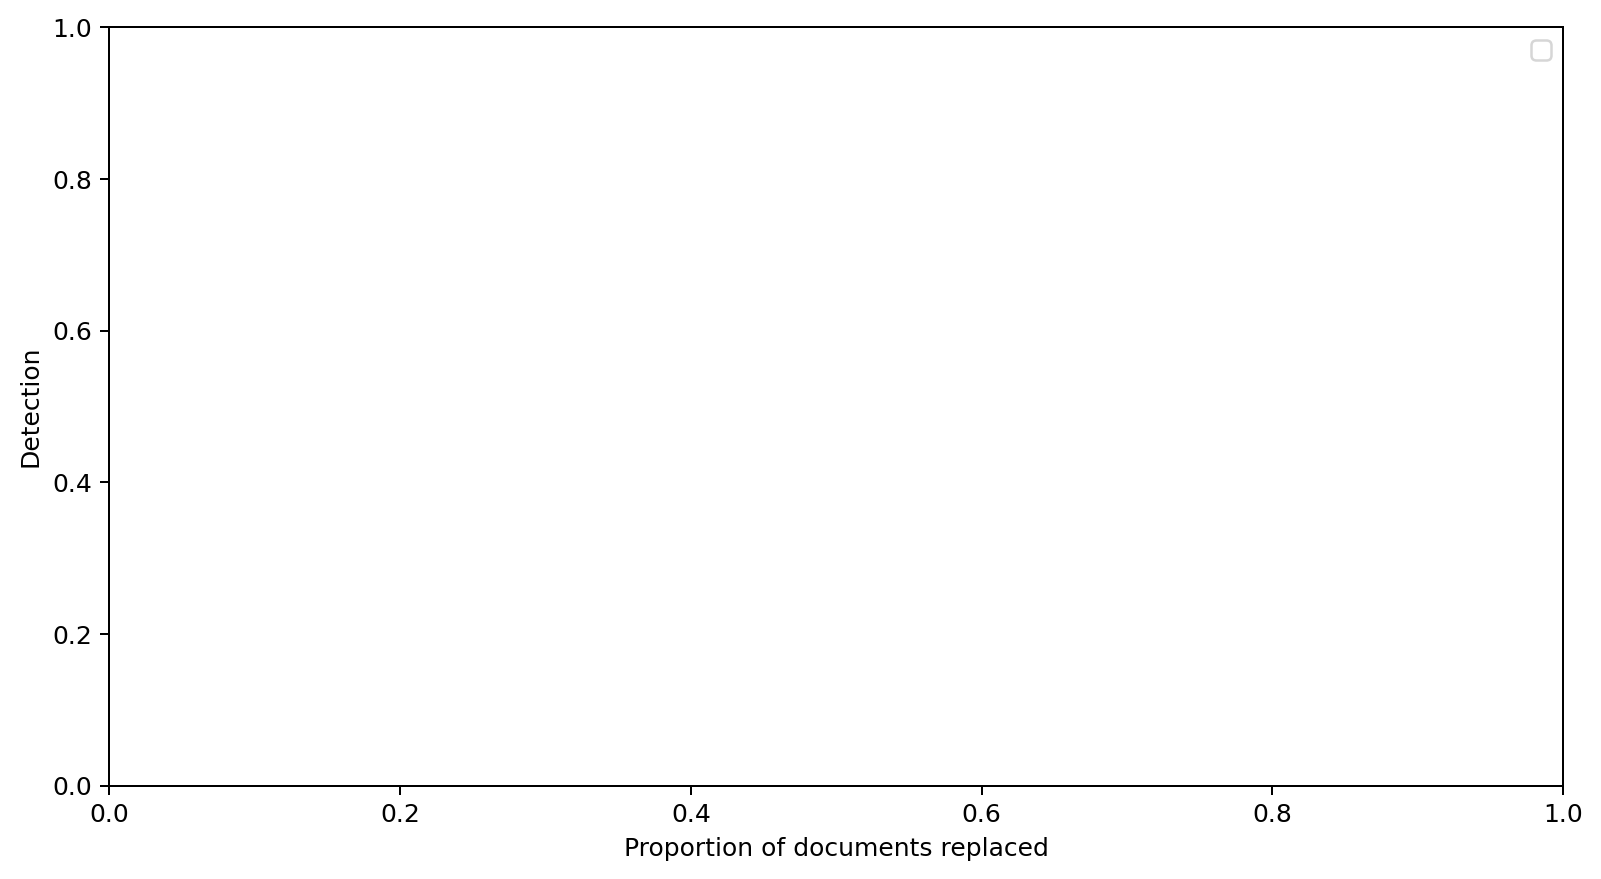


FIGURA 2: FIG_JOI_02_CALIBRATION.png
Origem: FIG_JOI_02_CALIBRATION.png


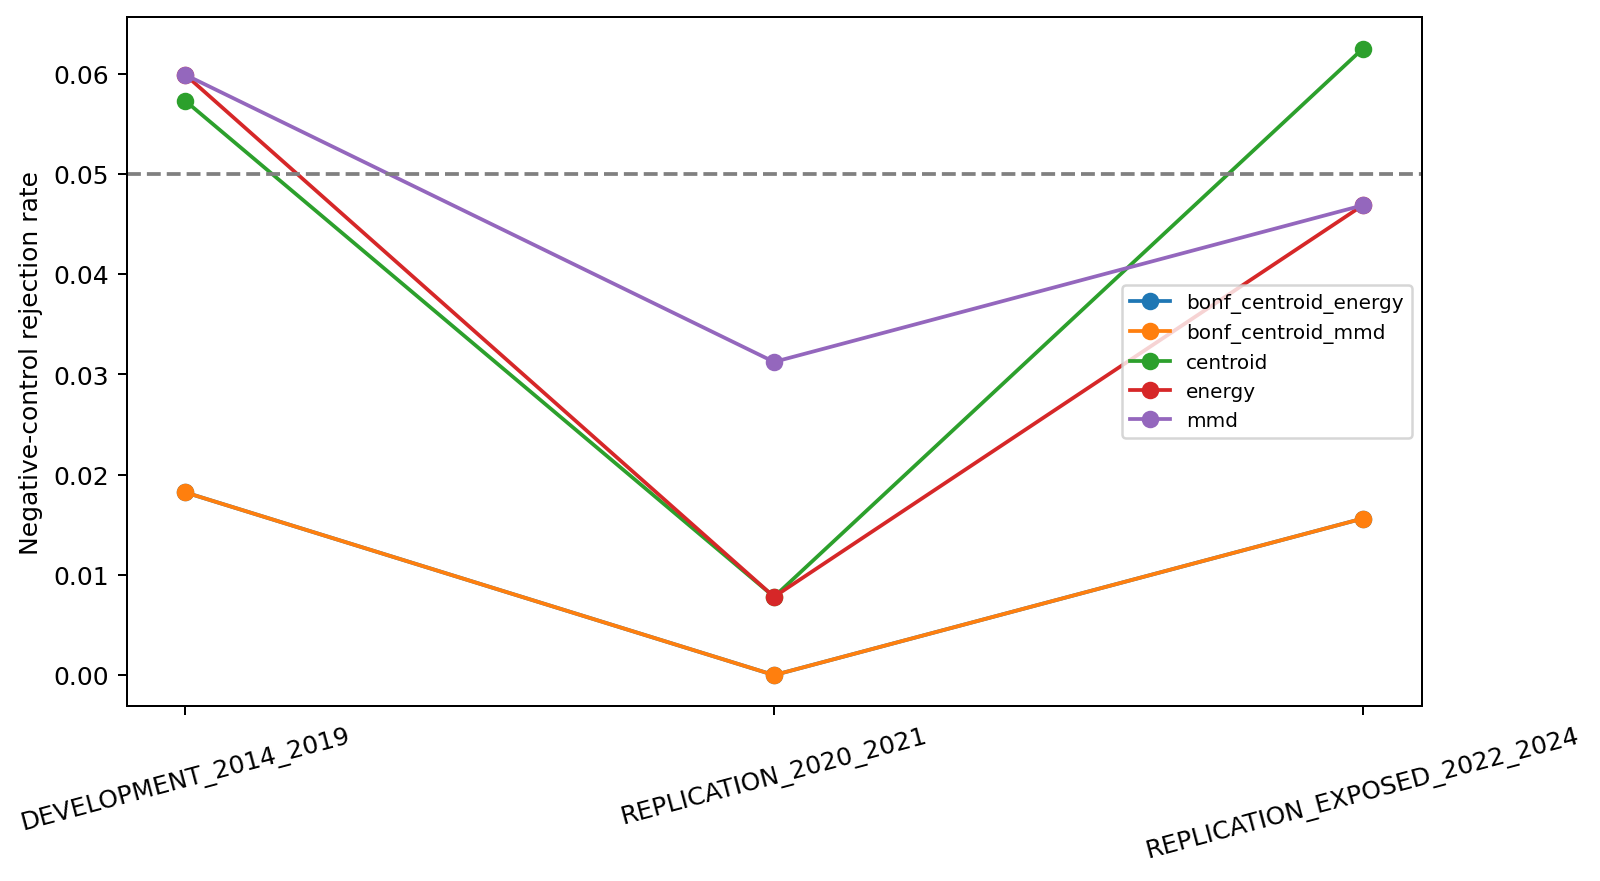


LAB-JOI 99 — EXPORTAÇÃO CONCLUÍDA
Tabelas principais selecionadas: 5
CSV/JSON copiados: 8
Figuras copiadas: 2
Arquivo TXT: /content/LAB_JOI_99_EXPORT_FOR_MANUSCRIPT/LAB_JOI_99_RESULTS_FOR_MANUSCRIPT.txt
Arquivo ZIP: /content/LAB_JOI_99_RESULTS_FOR_ARTICLE.zip
ZIP tamanho (MB): 0.38
Integridade ZIP: PASS

Iniciando download do ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# =====================================================================
# LAB-JOI 99 — EXPORTAÇÃO E APRESENTAÇÃO COMPLETA DOS RESULTADOS
# Executar no Google Colab — CPU
# Não modifica nenhuma saída congelada do laboratório.
# =====================================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, Image, Markdown
import pandas as pd
import numpy as np
import json
import zipfile
import shutil
import hashlib
import re

try:
    from google.colab import drive, files
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

ROOT = Path(
    "/content/drive/MyDrive/CAPES_Epistemic_Change/"
    "99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1"
)

assert ROOT.is_dir(), f"Diretório LAB-JOI 99 não encontrado: {ROOT}"

OUT = Path("/content/LAB_JOI_99_EXPORT_FOR_MANUSCRIPT")
OUT.mkdir(parents=True, exist_ok=True)

TABLES = OUT / "tables"
FIGURES = OUT / "figures"
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.expand_frame_repr", False)

print("=" * 78)
print("LAB-JOI 99 — RELATÓRIO PARA MANUSCRITO")
print("=" * 78)
print("Origem:", ROOT)
print("Destino:", OUT)
print("Execução: CPU | somente leitura dos resultados originais")

# ---------------------------------------------------------------------
# 1. INVENTÁRIO E DESCOBERTA DOS ARQUIVOS REAIS
# ---------------------------------------------------------------------

all_files = sorted(
    p for p in ROOT.rglob("*")
    if p.is_file()
)

candidate_tables = [
    p for p in all_files
    if p.suffix.lower() in (".csv", ".parquet")
]

candidate_figures = [
    p for p in all_files
    if p.suffix.lower() in (".png", ".jpg", ".jpeg", ".pdf", ".svg")
]

print("\nARQUIVOS DE TABELAS ENCONTRADOS:", len(candidate_tables))
print("FIGURAS ENCONTRADAS:", len(candidate_figures))

for p in candidate_tables:
    print("TABLE:", p.relative_to(ROOT))

for p in candidate_figures:
    print("FIG:", p.relative_to(ROOT))

# ---------------------------------------------------------------------
# 2. CARREGAMENTO DAS TABELAS DE RESULTADOS
# ---------------------------------------------------------------------

# Prioridade dos principais produtos previstos para o LAB-JOI 99.
# Caso o nome real seja diferente, a descoberta é feita pelo conteúdo
# do nome e TODAS as tabelas CSV são preservadas no pacote final.

CATEGORIES = {
    "01_CALIBRATION_POWER": [
        "CALIBRATION_POWER",
        "POWER_CLUSTER",
        "CALIBRATION",
    ],
    "02_PAIRED_GAINS": [
        "PAIRED_GAINS",
        "PAIRED_GAIN",
        "EXACT_TESTS",
        "MCNEMAR",
    ],
    "03_NEGATIVE_CONTROLS": [
        "NULL_CALIBRATION",
        "NEGATIVE_CONTROL",
        "RAW_REPLICATE_NULL",
    ],
    "04_COMPOSITE_RULES": [
        "COMPOSITE",
        "COMBINED",
        "BONFERRONI",
    ],
    "05_GEOMETRY": [
        "GEOMETRY",
        "DISPERSION",
    ],
    "06_FINAL_HANDOFF": [
        "FINAL_HANDOFF",
    ],
}

def read_table(path):
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    if path.suffix.lower() == ".parquet":
        return pd.read_parquet(path)
    raise ValueError(f"Formato não suportado: {path}")

def select_file(patterns):
    hits = [
        p for p in candidate_tables
        if any(pattern in p.name.upper() for pattern in patterns)
    ]
    # Prioriza agregados CSV, em vez de tabelas brutas volumosas.
    hits = sorted(
        hits,
        key=lambda p: (
            0 if p.suffix.lower() == ".csv" else 1,
            len(p.name),
            str(p)
        )
    )
    return hits[0] if hits else None

selected = {}

for category, patterns in CATEGORIES.items():
    path = select_file(patterns)
    if path:
        selected[category] = path

report_lines = []

def report(text=""):
    value = str(text)
    print(value)
    report_lines.append(value)

def show_table(title, df, max_rows=50):
    report("\n" + "=" * 90)
    report(title)
    report("=" * 90)
    report(f"LINHAS: {len(df)} | COLUNAS: {len(df.columns)}")
    report("COLUNAS: " + " | ".join(map(str, df.columns)))

    if len(df) <= max_rows:
        view = df
    else:
        view = df.head(max_rows)
        report(
            f"Exibindo as primeiras {max_rows} linhas. "
            "A tabela integral será incluída no ZIP."
        )

    # to_string impede a supressão de colunas pela formatação do Pandas.
    report(view.to_string(index=False, max_cols=None))

print("\n" + "=" * 78)
print("TABELAS SELECIONADAS")
print("=" * 78)

loaded = {}

for category, path in selected.items():
    try:
        if path.suffix.lower() in (".csv", ".parquet"):
            df = read_table(path)
            loaded[category] = df

            # Limites específicos de exibição para impedir truncamento do Colab.
            max_rows = 45 if len(df) > 100 else 100
            show_table(
                f"{category} — {path.name}",
                df,
                max_rows=max_rows
            )
        else:
            report(f"{category}: {path.name}")
    except Exception as exc:
        report(f"ERRO ao ler {path.name}: {exc}")

# ---------------------------------------------------------------------
# 3. TABELAS COMPLETAS ADICIONAIS DE CALIBRAÇÃO E PODER
# ---------------------------------------------------------------------

print("\n" + "=" * 78)
print("RESUMOS POR MODELO, PERÍODO, CENÁRIO E REGRA")
print("=" * 78)

grouped_exports = []

for category, df in loaded.items():
    if not isinstance(df, pd.DataFrame) or df.empty:
        continue

    candidate_groups = [
        c for c in [
            "model", "phase", "scenario", "intensity",
            "rule", "method", "size_band"
        ]
        if c in df.columns
    ]

    numeric_columns = [
        c for c in [
            "mean_rejection", "rejection_rate", "rate",
            "power", "detection", "mean_gain",
            "difference", "low95", "high95"
        ]
        if c in df.columns and pd.api.types.is_numeric_dtype(df[c])
    ]

    if candidate_groups and numeric_columns:
        # Não agregamos fases ou modelos indiscriminadamente.
        groups = candidate_groups[:6]

        summary = (
            df.groupby(groups, dropna=False, observed=True)
              [numeric_columns]
              .mean()
              .reset_index()
        )

        target = TABLES / f"{category}_GROUPED_SUMMARY.csv"
        summary.to_csv(target, index=False)
        grouped_exports.append(target)

        if len(summary) <= 65:
            show_table(
                f"RESUMO ESTRATIFICADO — {category}",
                summary,
                max_rows=65
            )
        else:
            report(
                f"\n{category}: {len(summary)} estratos; "
                f"arquivo integral salvo em {target.name}"
            )

# ---------------------------------------------------------------------
# 4. CONFERÊNCIA DE TESTES COMBINADOS E CONTROLES
# ---------------------------------------------------------------------

report("\n" + "=" * 90)
report("VERIFICAÇÕES DE INTERPRETAÇÃO")
report("=" * 90)

report(
    "Os resultados são comparações sobre pares selecionados; "
    "não estimam prevalência nacional de mudanças científicas."
)
report(
    "Os quatro modelos usam o mesmo conjunto documental e "
    "não constituem quatro amostras independentes."
)
report(
    "As regras combinadas devem ser avaliadas conjuntamente por "
    "calibração dos controles negativos e poder sob intervenção."
)
report(
    "A existência de diferenças entre regras não demonstra "
    "inovação matemática original."
)
report(
    "A fase 2022–2024 já foi exposta anteriormente e não deve "
    "ser apresentada como teste confirmatório intocado."
)

# ---------------------------------------------------------------------
# 5. CÓPIA ÍNTEGRA DE TODOS OS CSV E JSON DE SÍNTESE
# ---------------------------------------------------------------------

copied_tables = []

for p in all_files:
    if p.suffix.lower() not in (".csv", ".json"):
        continue

    rel = p.relative_to(ROOT)
    safe_name = "__".join(rel.parts)

    destination = TABLES / safe_name
    shutil.copy2(p, destination)
    copied_tables.append(destination)

report(f"\nCSV/JSON preservados no pacote: {len(copied_tables)}")

# Inclui um resumo do layout dos Parquets, sem copiar bases privadas
# potencialmente volumosas ou identificadores individuais.
schemas = []

for p in candidate_tables:
    if p.suffix.lower() != ".parquet":
        continue

    try:
        import pyarrow.parquet as pq
        meta = pq.ParquetFile(p).metadata
        schema = pq.read_schema(p)

        schemas.append({
            "file": str(p.relative_to(ROOT)),
            "rows": meta.num_rows,
            "columns": list(schema.names),
            "size_bytes": p.stat().st_size
        })
    except Exception as exc:
        schemas.append({
            "file": str(p.relative_to(ROOT)),
            "error": str(exc)
        })

(OUT / "PARQUET_SCHEMA_INVENTORY.json").write_text(
    json.dumps(schemas, ensure_ascii=False, indent=2, default=str),
    encoding="utf-8"
)

# ---------------------------------------------------------------------
# 6. FIGURAS — EXIBIR E PRESERVAR ARQUIVOS ORIGINAIS
# ---------------------------------------------------------------------

report("\n" + "=" * 90)
report("FIGURAS GERADAS PELO LAB-JOI 99")
report("=" * 90)

copied_figures = []

for i, p in enumerate(candidate_figures, start=1):
    rel = p.relative_to(ROOT)
    safe_name = "__".join(rel.parts)
    dest = FIGURES / safe_name

    shutil.copy2(p, dest)
    copied_figures.append(dest)

    report(f"\nFIGURA {i}: {p.name}")
    report(f"Origem: {rel}")

    if p.suffix.lower() in (".png", ".jpg", ".jpeg"):
        try:
            display(Image(filename=str(p), width=850))
        except Exception as exc:
            report(f"Não foi possível exibir: {exc}")
    else:
        report(
            "Arquivo preservado no pacote. "
            "Formato não exibido inline nesta célula."
        )

# ---------------------------------------------------------------------
# 7. RELATÓRIO TEXTUAL INTEGRAL
# ---------------------------------------------------------------------

text_path = OUT / "LAB_JOI_99_RESULTS_FOR_MANUSCRIPT.txt"

text_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

# ---------------------------------------------------------------------
# 8. MANIFESTO SHA-256 DOS ARQUIVOS EXPORTADOS
# ---------------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

manifest = []

for p in sorted(OUT.rglob("*")):
    if p.is_file():
        manifest.append({
            "file": str(p.relative_to(OUT)),
            "bytes": p.stat().st_size,
            "sha256": sha256(p)
        })

(OUT / "EXPORT_MANIFEST_SHA256.json").write_text(
    json.dumps(
        {
            "source": str(ROOT),
            "generated_utc": datetime.now(timezone.utc).isoformat(),
            "files": manifest
        },
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------------------
# 9. ZIP PARA COMPARTILHAR NO CHATGPT
# ---------------------------------------------------------------------

zip_path = Path("/content/LAB_JOI_99_RESULTS_FOR_ARTICLE.zip")

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as z:
    for p in sorted(OUT.rglob("*")):
        if p.is_file():
            z.write(p, arcname=str(p.relative_to(OUT)))

with zipfile.ZipFile(zip_path) as z:
    bad = z.testzip()

assert bad is None, f"Falha de integridade ZIP: {bad}"

print("\n" + "=" * 78)
print("LAB-JOI 99 — EXPORTAÇÃO CONCLUÍDA")
print("=" * 78)

print("Tabelas principais selecionadas:", len(loaded))
print("CSV/JSON copiados:", len(copied_tables))
print("Figuras copiadas:", len(copied_figures))
print("Arquivo TXT:", text_path)
print("Arquivo ZIP:", zip_path)
print("ZIP tamanho (MB):", round(zip_path.stat().st_size / 1024**2, 2))
print("Integridade ZIP: PASS")

if IN_COLAB:
    print("\nIniciando download do ZIP...")
    files.download(str(zip_path))
else:
    print("\nFora do Colab: utilize o caminho informado acima.")


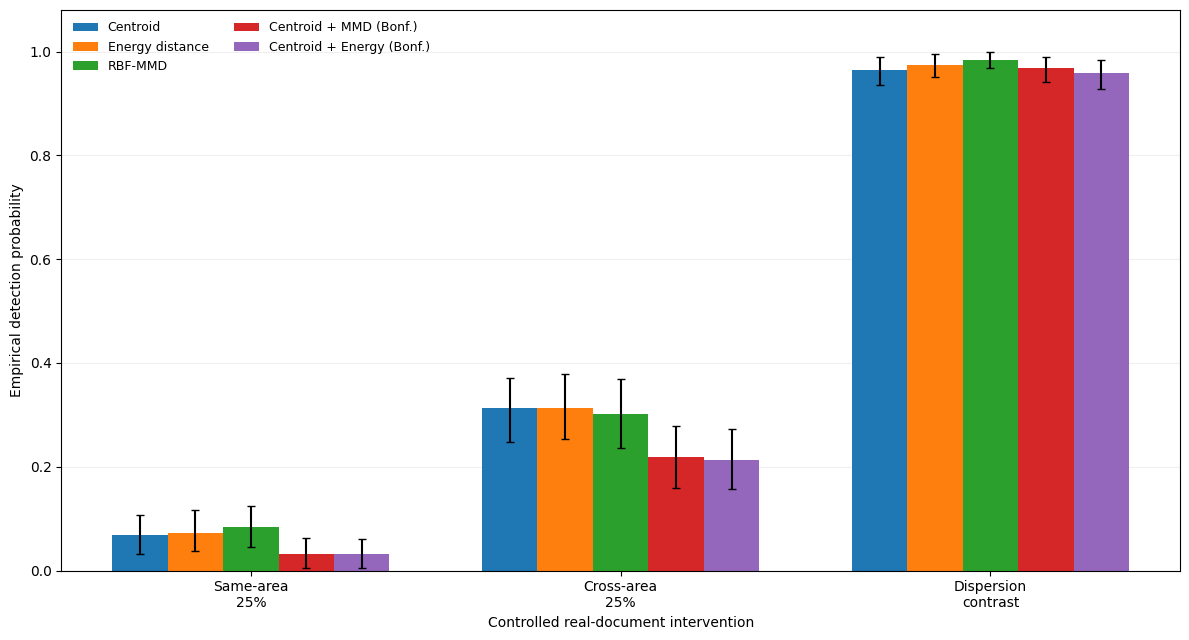

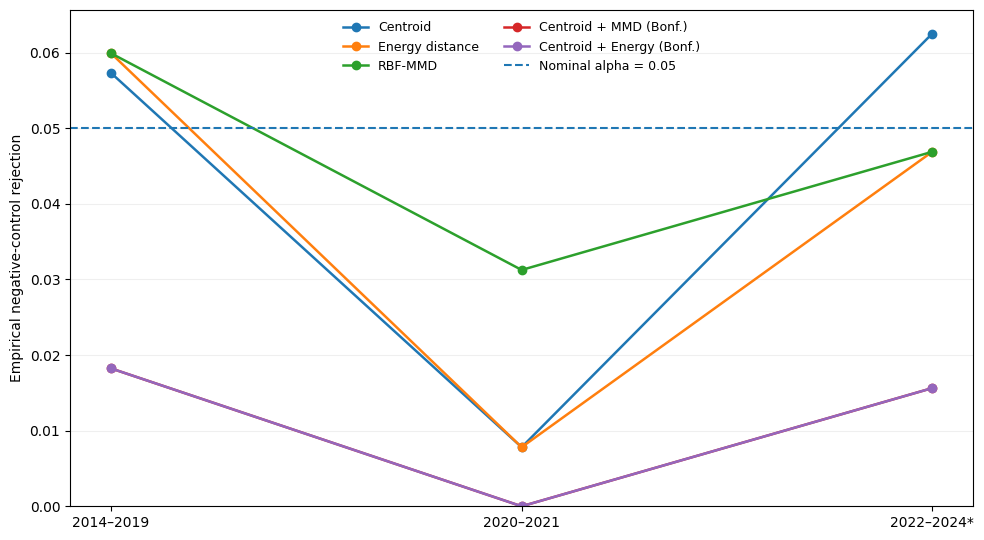

FIGURES CORRECTED — PASS
Output: /content/drive/MyDrive/CAPES_Epistemic_Change/99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1/10_JOI_PUBLICATION_FIGURES_CORRECTED
Data rows: 20


,scenario,method,n_pairs,n_ppg,detection,low95,high95
4,different_area_replace_25,bonf_centroid_energy,192,181,0.2135,0.1562,0.2727
3,different_area_replace_25,bonf_centroid_mmd,192,181,0.2188,0.1587,0.2789
0,different_area_replace_25,centroid,192,181,0.3125,0.2473,0.3717
1,different_area_replace_25,energy,192,181,0.3125,0.2526,0.3782
2,different_area_replace_25,mmd,192,181,0.3021,0.2368,0.3698
9,negative,bonf_centroid_energy,192,181,0.0182,0.0054,0.0328
8,negative,bonf_centroid_mmd,192,181,0.0182,0.0074,0.0314
5,negative,centroid,192,181,0.0573,0.0340,0.0812
6,negative,energy,192,181,0.0599,0.0374,0.0846
7,negative,mmd,192,181,0.0599,0.0368,0.0838


In [ ]:

# LAB-JOI 99 — FIGURAS CORRIGIDAS PARA PUBLICAÇÃO
# Google Colab | CPU | leitura somente dos CSVs existentes

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(
    "/content/drive/MyDrive/CAPES_Epistemic_Change/"
    "99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1"
)
OUT = ROOT / "10_JOI_PUBLICATION_FIGURES_CORRECTED"
OUT.mkdir(parents=True, exist_ok=True)

f_power = ROOT / "03_JOI_CALIBRATION_POWER_CLUSTER_CI.csv"
f_null = ROOT / "05_JOI_RAW_REPLICATE_NULL_CALIBRATION.csv"
assert f_power.exists(), f"Missing: {f_power}"
assert f_null.exists(), f"Missing: {f_null}"

power = pd.read_csv(f_power)
null = pd.read_csv(f_null)

METHODS = [
    "centroid",
    "energy",
    "mmd",
    "bonf_centroid_mmd",
    "bonf_centroid_energy",
]
LABELS = {
    "centroid": "Centroid",
    "energy": "Energy distance",
    "mmd": "RBF-MMD",
    "bonf_centroid_mmd": "Centroid + MMD (Bonf.)",
    "bonf_centroid_energy": "Centroid + Energy (Bonf.)",
}
SCENARIOS = [
    "same_area_replace_25",
    "different_area_replace_25",
    "real_vector_dispersion_contrast",
]
SCENARIO_LABELS = [
    "Same-area\n25%",
    "Cross-area\n25%",
    "Dispersion\ncontrast",
]
PHASES = [
    "DEVELOPMENT_2014_2019",
    "REPLICATION_2020_2021",
    "REPLICATION_EXPOSED_2022_2024",
]
PHASE_LABELS = ["2014–2019", "2020–2021", "2022–2024*"]

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=400, bbox_inches="tight")
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    display(fig)
    plt.close(fig)

# FIGURA 1 — PODER POR CENÁRIO (M1, DESENVOLVIMENTO)
d = power[
    (power["model"] == "M1") &
    (power["phase"] == PHASES[0]) &
    power["scenario"].isin(SCENARIOS) &
    power["method"].isin(METHODS)
].copy()

expected = len(SCENARIOS) * len(METHODS)
assert len(d) == expected, (
    f"Expected {expected} rows, found {len(d)}; "
    "check the frozen table before plotting."
)

x = np.arange(len(SCENARIOS))
fig, ax = plt.subplots(figsize=(12, 6.5))
width = 0.15

for j, method in enumerate(METHODS):
    sub = d[d["method"] == method].set_index("scenario")
    sub = sub.loc[SCENARIOS]

    values = sub["detection"].to_numpy(dtype=float)
    lows = sub["low95"].to_numpy(dtype=float)
    highs = sub["high95"].to_numpy(dtype=float)

    ax.bar(
        x + (j - 2) * width, values, width,
        label=LABELS[method],
        yerr=np.array([values - lows, highs - values]),
        capsize=3,
    )

ax.set_xticks(x)
ax.set_xticklabels(SCENARIO_LABELS)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Empirical detection probability")
ax.set_xlabel("Controlled real-document intervention")
ax.legend(frameon=False, ncol=2, fontsize=9)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
save(fig, "JOI99_FIG01_DETECTION_BY_METHOD_SCENARIO")

# FIGURA 2 — CALIBRAÇÃO POR PERÍODO (TODOS OS MÉTODOS, M1)
d = null[
    (null["model"] == "M1") &
    null["phase"].isin(PHASES) &
    null["method"].isin(METHODS)
].copy()

assert len(d) == len(PHASES) * len(METHODS), (
    "Incomplete negative-control cells."
)

fig, ax = plt.subplots(figsize=(10, 5.5))
xx = np.arange(len(PHASES))

for method in METHODS:
    sub = d[d["method"] == method].set_index("phase")
    sub = sub.loc[PHASES]

    ax.plot(
        xx, sub["empirical_rejection"].to_numpy(),
        marker="o",
        linewidth=1.8,
        label=LABELS[method],
    )

ax.axhline(
    0.05, linestyle="--", linewidth=1.5,
    label="Nominal alpha = 0.05",
)
ax.set_xticks(xx)
ax.set_xticklabels(PHASE_LABELS)
ax.set_ylabel("Empirical negative-control rejection")
ax.set_ylim(bottom=0)
ax.legend(frameon=False, fontsize=9, ncol=2)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save(fig, "JOI99_FIG02_NEGATIVE_CONTROL_CALIBRATION")

# TABELA PARA ACOMPANHAR AS DUAS FIGURAS
subset = power[
    (power["model"] == "M1") &
    (power["phase"] == PHASES[0]) &
    power["scenario"].isin(["negative"] + SCENARIOS)
].copy()

cols = [
    "scenario", "method", "n_pairs", "n_ppg",
    "detection", "low95", "high95"
]
subset = subset[cols].sort_values(["scenario", "method"])
subset.to_csv(
    OUT / "JOI99_FIGURE_SOURCE_DATA.csv", index=False
)

print("FIGURES CORRECTED — PASS")
print("Output:", OUT)
print("Data rows:", len(subset))
display(subset.round(4))


# Conditional measurement resolution and method-substitution risk

In [ ]:
# 01 — Setup, input contracts, output manifest
from pathlib import Path
import sys, subprocess, json, hashlib, warnings, time
import numpy as np, pandas as pd
from scipy.special import expit
from scipy.stats import beta
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import GroupKFold
from sklearn.metrics import brier_score_loss, log_loss
from IPython.display import display
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
BASE=Path('/content/drive/MyDrive/CAPES_Epistemic_Change')
P99=BASE/'99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1'
OUT=BASE/'100JOI_LAB04_CONDITIONAL_RESOLUTION_V1'
OUT.mkdir(parents=True,exist_ok=True)
P94_CANDIDATES=sorted(p for p in BASE.iterdir() if p.is_dir() and '94B' in p.name and 'LAB04' in p.name)
if not P94_CANDIDATES:
    raise FileNotFoundError('Stage 94B directory not found; do not guess or rebuild frozen inputs.')
P94_MATCH=[p for p in P94_CANDIDATES if (p/'07_CONTROL_REPLICATES_ALL.parquet').exists() and (p/'06_OBSERVED_ALL_MODELS_PHASES.parquet').exists()]
if len(P94_MATCH)!=1:
    raise RuntimeError(f'Exactly one 94B source required, found {len(P94_MATCH)}: {[str(p) for p in P94_MATCH]}')
P94=P94_MATCH[0]
C94=P94/'07_CONTROL_REPLICATES_ALL.parquet'; O94=P94/'06_OBSERVED_ALL_MODELS_PHASES.parquet'
W99=P99/'01_JOI_RAW_PAIRED_COMPOSITES_PRIVATE.parquet'
for p in [C94,O94,W99]:
    if not p.is_file(): raise FileNotFoundError(str(p))
def sha256(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1<<20),b''):h.update(b)
    return h.hexdigest()
INPUTS={p.name:{'path':str(p),'sha256':sha256(p),'size_bytes':p.stat().st_size} for p in [C94,O94,W99]}
print('94B:',P94,'99:',P99,'output:',OUT,sep='\n')
print('Frozen input fingerprints:',json.dumps(INPUTS,indent=2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
94B:
/content/drive/MyDrive/CAPES_Epistemic_Change/94B_LAB04_JDIS_FULL_2013_2024_COMPUTATIONAL_REPLICATION_V1
99:
/content/drive/MyDrive/CAPES_Epistemic_Change/99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1
output:
/content/drive/MyDrive/CAPES_Epistemic_Change/100JOI_LAB04_CONDITIONAL_RESOLUTION_V1
Frozen input fingerprints: {
  "07_CONTROL_REPLICATES_ALL.parquet": {
    "path": "/content/drive/MyDrive/CAPES_Epistemic_Change/94B_LAB04_JDIS_FULL_2013_2024_COMPUTATIONAL_REPLICATION_V1/07_CONTROL_REPLICATES_ALL.parquet",
    "sha256": "5445ace9d852b2c4e7039eaf2866850576dc37472401b2c25935c84fb949a507",
    "size_bytes": 472697
  },
  "06_OBSERVED_ALL_MODELS_PHASES.parquet": {
    "path": "/content/drive/MyDrive/CAPES_Epistemic_Change/94B_LAB04_JDIS_FULL_2013_2024_COMPUTATIONAL_REPLICATION_V1/06_OBSERVED_ALL_MODELS_PHASES.parquet",
    "sha256": "9c488fa998fbca

In [ ]:
# 02 — Audited loading; preserve independent experimental units
controls=pd.read_parquet(C94)
obs=pd.read_parquet(O94)
wide=pd.read_parquet(W99)
need94={'model','phase','pair_id','ppg','year','size_band','control','intensity','rep','rejected'}
needobs={'model','phase','pair_id','ppg','year','n_a','n_b'}
need99={'model','phase','year','ppg','pair_id','size_band','scenario','intensity','rep',
 'centroid_reject','energy_reject','mmd_reject','bonf_cm_reject','bonf_ce_reject'}
for label,df,req in [('94B-controls',controls,need94),('94B-observed',obs,needobs),('99-wide',wide,need99)]:
    miss=req-set(df.columns)
    if miss:raise ValueError(f'{label}: missing required columns {sorted(miss)}')
KEY=['model','phase','pair_id','ppg','year']
assert not obs.duplicated(KEY).any(),'94B observed size mapping not unique'
assert not controls.duplicated(KEY+['control','intensity','rep']).any(),'94B control replicates not unique'
assert not wide.duplicated(KEY+['scenario','intensity','rep']).any(),'99 paired decisions not unique'
control_size=controls.merge(obs[KEY+['n_a','n_b']],on=KEY,how='left',validate='many_to_one',indicator=True)
assert (control_size['_merge']=='both').all(),'Unmatched 94B controls-to-observed sizes'
control_size.drop(columns='_merge',inplace=True)
for name,df in [('controls',control_size),('99 decisions',wide)]:
    print(name,'rows',len(df),'models',sorted(df.model.unique()),'phases',df.phase.value_counts().to_dict())
assert len(obs)==1408 and len(control_size)==8448 and len(wide)==8448
assert set(wide.model)==set(controls.model)=={'M1','M2','M3','M4'}
print('94B condition x intensity counts:',control_size.groupby(['control','intensity'],dropna=False).size().to_dict())
print('99 scenario x repeat counts:',wide.groupby('scenario').size().to_dict())

controls rows 8448 models ['M1', 'M2', 'M3', 'M4'] phases {'DEVELOPMENT_2014_2019': 4608, 'REPLICATION_EXPOSED_2022_2024': 2304, 'REPLICATION_2020_2021': 1536}
99 decisions rows 8448 models ['M1', 'M2', 'M3', 'M4'] phases {'DEVELOPMENT_2014_2019': 4608, 'REPLICATION_EXPOSED_2022_2024': 2304, 'REPLICATION_2020_2021': 1536}
94B condition x intensity counts: {('negative', 0.0): 4224, ('positive', 0.1): 1408, ('positive', 0.25): 1408, ('positive', 0.5): 1408}
99 scenario x repeat counts: {'different_area_replace_25': 1408, 'negative': 2816, 'observed': 1408, 'real_vector_dispersion_contrast': 1408, 'same_area_replace_25': 1408}


In [ ]:
# 03 — Conditional power model, with cluster-robust uncertainty and blocked cross-validation
# A separate empirical logistic fit by encoder, development phase only.
# Observed continuous size: min(n_a,n_b); intensity categories 0.1/0.25/0.5.
# Uses all positive-control replicates; measures within-design conditional power, not causal effect.
dev=control_size[(control_size.phase=='DEVELOPMENT_2014_2019') & (control_size.control=='positive')].copy()
dev['n_effective']=dev[['n_a','n_b']].min(axis=1).astype(float)
dev['log_n']=np.log(dev.n_effective)
dev['delta']=dev.intensity.astype(float)
dev['y']=dev.rejected.astype(float)
assert set(np.round(dev.delta.unique(),5))=={0.1,0.25,0.5}, 'Unexpected 94B positive intensities: inspect input'
assert dev['n_effective'].ge(2).all()
# Design: log sample size, intensity contrasts, size-by-intensity interaction.
# No extrapolation to unobserved intensities; levels treated categorically.
levels=[0.1,0.25,0.5]
def build_x(df):
    v=pd.DataFrame({'intercept':np.ones(len(df)),'log_n':np.log(df.n_effective.to_numpy())},index=df.index)
    for d in [0.25,0.5]:
        key='delta_'+str(d).replace('.','_')
        v[key]=(np.isclose(df.delta.to_numpy(),d)).astype(float)
        v[key+'_x_logn']=v[key].to_numpy()*v.log_n.to_numpy()
    return v
# Validation grouped by programme, not individual replicate.
fit_results=[]; cv_rows=[]; curves=[]
for model,g in dev.groupby('model'):
    g=g.reset_index(drop=True); X=build_x(g); y=g.y
    if y.nunique()!=2:raise RuntimeError(f'{model}: no outcome variability')
    glm=sm.GLM(y,X,family=sm.families.Binomial())
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        result=glm.fit(cov_type='cluster',cov_kwds={'groups':g.ppg.to_numpy()},maxiter=150)
    for term in X.columns:
        fit_results.append({'model':model,'term':term,'estimate':result.params[term],
         'robust_se':result.bse[term], 'low95':result.conf_int().loc[term,0],
         'high95':result.conf_int().loc[term,1]})
    k=min(5,g.ppg.nunique())
    cv=GroupKFold(n_splits=k)
    for fold,(tr,te) in enumerate(cv.split(X,y,groups=g.ppg),start=1):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            try:
                fit=sm.GLM(y.iloc[tr],X.iloc[tr],family=sm.families.Binomial()).fit(maxiter=150)
                pred=np.clip(fit.predict(X.iloc[te]),1e-6,1-1e-6)
                cv_rows.append({'model':model,'fold':fold,'n_test':len(te),
                     'n_programmes_test':g.ppg.iloc[te].nunique(),
                     'brier':brier_score_loss(y.iloc[te],pred),
                     'logloss':log_loss(y.iloc[te],pred,labels=[0,1])})
            except Exception as exc:
                cv_rows.append({'model':model,'fold':fold,'error':str(exc)})
    lo,hi=int(np.ceil(g.n_effective.min())),int(np.floor(g.n_effective.max()))
    for delta in levels:
        new=pd.DataFrame({'n_effective':np.arange(lo,hi+1,dtype=float),'delta':delta})
        pr=result.get_prediction(build_x(new)).summary_frame(alpha=.05)
        for i,row in new.iterrows():
            curves.append({'model':model,'delta':delta,'n_effective':int(row.n_effective),
             'power_hat':float(pr.iloc[i]['mean']), 'low95':float(pr.iloc[i]['mean_ci_lower']),
             'high95':float(pr.iloc[i]['mean_ci_upper']),'scope':'IN_SAMPLE_RANGE_MODEL_BASED'})
pd.DataFrame(fit_results).to_csv(OUT/'01_GLM_COEFFICIENTS_CLUSTER_SE.csv',index=False)
pd.DataFrame(cv_rows).to_csv(OUT/'02_BLOCKED_CROSS_VALIDATION.csv',index=False)
curves=pd.DataFrame(curves)
curves.to_csv(OUT/'03_CONDITIONAL_POWER_CURVES_MODEL_BASED.csv',index=False)
display(pd.DataFrame(cv_rows).groupby('model',dropna=False)[['brier','logloss']].mean().round(4))

,brier,logloss
model,,
M1,0.1175,0.3731
M2,0.1062,0.3498
M3,0.0937,0.3085
M4,0.0846,0.2818


In [ ]:
# 04 — Honest resolution frontier (n for 80% power); null calibration separately
# Threshold is supported only when the 80% target falls inside tested n range
# with a monotone increasing fitted curve; never infer n50 or n80 across unsampled intensity levels.
frontiers=[]
for (model,delta),g in curves.groupby(['model','delta']):
    g=g.sort_values('n_effective'); x=g.n_effective.to_numpy(); y=g.power_hat.to_numpy()
    monotone=bool(np.all(np.diff(y)>=-1e-8))
    meets=g[g.power_hat>=0.8]
    if monotone and len(meets)>0:
        candidate=meets.iloc[0]
        status='DESCRIPTIVE_MODEL_BASED_WITHIN_OBSERVED_N_RANGE'
        n80=int(candidate.n_effective)
        # Is lower CI >= .8? stronger uncertainty-qualified support.
        robust=bool(candidate.low95>=.8)
    else:
        status='NOT_IDENTIFIED_WITHIN_OBSERVED_N_RANGE' if not len(meets) else 'NON_MONOTONIC_FIT_NO_UNIQUE_MINIMUM'
        n80=np.nan;robust=False
    frontiers.append({'model':model,'delta':delta,'n80_estimate':n80,'status':status,
      'lower95_at_n80_at_least_80pct':robust,'observed_n_min':int(x.min()),'observed_n_max':int(x.max()),
      'power_at_max_observed_n':float(y[-1]),'fit_monotone':monotone})
frontiers=pd.DataFrame(frontiers)
frontiers.to_csv(OUT/'04_RESOLUTION_FRONTIER_N80.csv',index=False)
# Calibration check: actual negatives are not true historical-change labels.
null=control_size[(control_size.phase=='DEVELOPMENT_2014_2019') & (control_size.control=='negative')]
null_rates=(null.groupby(['model','size_band'],dropna=False).agg(
 negative_rejection=('rejected','mean'),n_replicates=('rejected','size'),n_ppg=('ppg','nunique')
).reset_index())
null_rates.to_csv(OUT/'05_EMPIRICAL_NULL_BY_SIZE.csv',index=False)
display(frontiers)

,model,delta,n80_estimate,status,lower95_at_n80_at_least_80pct,observed_n_min,observed_n_max,power_at_max_observed_n,fit_monotone
0,M1,0.10,NaN,NOT_IDENTIFIED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.372047,True
1,M1,0.25,46.0,DESCRIPTIVE_MODEL_BASED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.974448,True
2,M1,0.50,15.0,DESCRIPTIVE_MODEL_BASED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.999900,True
3,M2,0.10,NaN,NOT_IDENTIFIED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.139451,True
4,M2,0.25,42.0,DESCRIPTIVE_MODEL_BASED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.986673,True
5,M2,0.50,13.0,DESCRIPTIVE_MODEL_BASED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.999993,True
6,M3,0.10,NaN,NOT_IDENTIFIED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.184223,True
7,M3,0.25,33.0,DESCRIPTIVE_MODEL_BASED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.998624,True
8,M3,0.50,11.0,DESCRIPTIVE_MODEL_BASED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.999976,True
9,M4,0.10,NaN,NOT_IDENTIFIED_WITHIN_OBSERVED_N_RANGE,False,8,118,0.290783,True


In [ ]:
# 05 — Exact unit-level method discordance (NO rounding of negative replicas)
METHODS={'centroid':'centroid_reject','energy':'energy_reject','mmd':'mmd_reject',
'bonf_cm':'bonf_cm_reject','bonf_ce':'bonf_ce_reject'}
for col in METHODS.values():
    unique=set(pd.to_numeric(wide[col],errors='coerce').dropna().unique())
    if not unique.issubset({0,1}):raise ValueError(f'{col}: not binary: {unique}')
from itertools import combinations
# Use individual exact paired scenario–replicate units. For negative controls, both replicates survive.
rows=[]
for (model,phase,scenario),g in wide.groupby(['model','phase','scenario'],sort=True):
    for a,b in combinations(METHODS,2):
        xa=g[METHODS[a]].to_numpy(dtype=int);xb=g[METHODS[b]].to_numpy(dtype=int)
        only_a=int(((xa==1)&(xb==0)).sum());only_b=int(((xa==0)&(xb==1)).sum())
        rows.append({'model':model,'phase':phase,'scenario':scenario,'method_a':a,'method_b':b,
         'n_paired_units':len(g),'n_ppg':g.ppg.nunique(),
         'both':int(((xa==1)&(xb==1)).sum()),'only_a':only_a,'only_b':only_b,
         'neither':int(((xa==0)&(xb==0)).sum()),
         'discordance_rate':(only_a+only_b)/len(g),'directional_gain_b_minus_a':(only_b-only_a)/len(g)})
disc=pd.DataFrame(rows)
assert (disc[['both','only_a','only_b','neither']].sum(axis=1)==disc.n_paired_units).all()
disc.to_csv(OUT/'06_EXACT_PAIRED_DISCORDANCE.csv',index=False)
# Cluster bootstrap CI, preserving all pair/rep units of each PPG in each resample.
rng=np.random.default_rng(10099);boot=[];B=400
for (model,phase,scenario),g in wide.groupby(['model','phase','scenario'],sort=True):
    # PPG grouped sufficient statistics for pairwise disagreements
    groups=list(g.groupby('ppg',sort=False)); n=len(groups)
    if n<10:continue
    methodpairs=[('centroid','energy'),('centroid','mmd'),('centroid','bonf_cm'),('centroid','bonf_ce')]
    for a,b in methodpairs:
        a_col,b_col=METHODS[a],METHODS[b]
        stats=np.array([[len(h),int((h[a_col]!=h[b_col]).sum()),int((h[b_col]-h[a_col]).sum())] for _,h in groups],float)
        picks=rng.integers(0,n,size=(B,n)); sums=stats[picks].sum(axis=1)
        r_disc=sums[:,1]/sums[:,0];r_gain=sums[:,2]/sums[:,0]
        boot.append({'model':model,'phase':phase,'scenario':scenario,'method_a':a,'method_b':b,
           'n_ppg':n,'discord_low95':np.quantile(r_disc,.025),'discord_high95':np.quantile(r_disc,.975),
           'gain_low95':np.quantile(r_gain,.025),'gain_high95':np.quantile(r_gain,.975)})
boot=pd.DataFrame(boot);boot.to_csv(OUT/'07_DISCORDANCE_PPG_BOOTSTRAP.csv',index=False)
print('Decision rows',len(disc),'bootstrap cells',len(boot))
display(disc.query("model=='M1' and phase=='DEVELOPMENT_2014_2019' and scenario=='different_area_replace_25'").head(10))

Decision rows 600 bootstrap cells 240


,model,phase,scenario,method_a,method_b,n_paired_units,n_ppg,both,only_a,only_b,neither,discordance_rate,directional_gain_b_minus_a
0,M1,DEVELOPMENT_2014_2019,different_area_replace_25,centroid,energy,192,181,58,2,2,130,0.020833,0.000000
1,M1,DEVELOPMENT_2014_2019,different_area_replace_25,centroid,mmd,192,181,56,4,2,130,0.031250,-0.010417
2,M1,DEVELOPMENT_2014_2019,different_area_replace_25,centroid,bonf_cm,192,181,42,18,0,132,0.093750,-0.093750
3,M1,DEVELOPMENT_2014_2019,different_area_replace_25,centroid,bonf_ce,192,181,41,19,0,132,0.098958,-0.098958
4,M1,DEVELOPMENT_2014_2019,different_area_replace_25,energy,mmd,192,181,58,2,0,132,0.010417,-0.010417
5,M1,DEVELOPMENT_2014_2019,different_area_replace_25,energy,bonf_cm,192,181,42,18,0,132,0.093750,-0.093750
6,M1,DEVELOPMENT_2014_2019,different_area_replace_25,energy,bonf_ce,192,181,41,19,0,132,0.098958,-0.098958
7,M1,DEVELOPMENT_2014_2019,different_area_replace_25,mmd,bonf_cm,192,181,42,16,0,134,0.083333,-0.083333
8,M1,DEVELOPMENT_2014_2019,different_area_replace_25,mmd,bonf_ce,192,181,41,17,0,134,0.088542,-0.088542
9,M1,DEVELOPMENT_2014_2019,different_area_replace_25,bonf_cm,bonf_ce,192,181,41,1,0,150,0.005208,-0.005208


In [ ]:
# 06 — Positive predictive value under ASSUMED prevalences (not a national estimate)
# alpha and power must refer to the SAME method/setting; use Stage99 direct controls.
# Only scenario same-area vs different-area, M1 development.
alpha_data=pd.read_csv(P99/'05_JOI_RAW_REPLICATE_NULL_CALIBRATION.csv')
power_data=pd.read_csv(P99/'03_JOI_CALIBRATION_POWER_CLUSTER_CI.csv')
model='M1';phase='DEVELOPMENT_2014_2019';methods=['centroid','energy','mmd','bonf_centroid_mmd','bonf_centroid_energy']
ppv=[]
for method in methods:
    n=alpha_data.query('model==@model and phase==@phase and method==@method')
    if len(n)!=1:raise RuntimeError(f'Null missing or duplicate: {method}')
    alpha=float(n.iloc[0].empirical_rejection)
    for scenario in ['same_area_replace_25','different_area_replace_25']:
        q=power_data.query('model==@model and phase==@phase and method==@method and scenario==@scenario')
        if len(q)!=1:raise RuntimeError(f'Power missing or duplicate {method} {scenario}')
        power=float(q.iloc[0].detection)
        for prior in [.01,.05,.10,.25,.50]:
            denom=prior*power+(1-prior)*alpha
            ppv.append({'model':model,'phase':phase,'method':method,'alternative_scenario':scenario,
              'ASSUMED_prior_true_change':prior,'empirical_null_rejection':alpha,
              'experimental_detection_rate':power,'PPV_UNDER_ASSUMPTIONS':prior*power/denom if denom else np.nan})
ppv=pd.DataFrame(ppv)
ppv.to_csv(OUT/'08_PPV_SENSITIVITY_ASSUMPTIONS_ONLY.csv',index=False)
print('Do not report PPV as probability of true observed historical scientific change.')
display(ppv.head(10))

Do not report PPV as probability of true observed historical scientific change.


,model,phase,method,alternative_scenario,ASSUMED_prior_true_change,empirical_null_rejection,experimental_detection_rate,PPV_UNDER_ASSUMPTIONS
0,M1,DEVELOPMENT_2014_2019,centroid,same_area_replace_25,0.01,0.057292,0.067708,0.011797
1,M1,DEVELOPMENT_2014_2019,centroid,same_area_replace_25,0.05,0.057292,0.067708,0.058559
2,M1,DEVELOPMENT_2014_2019,centroid,same_area_replace_25,0.10,0.057292,0.067708,0.116071
3,M1,DEVELOPMENT_2014_2019,centroid,same_area_replace_25,0.25,0.057292,0.067708,0.282609
4,M1,DEVELOPMENT_2014_2019,centroid,same_area_replace_25,0.50,0.057292,0.067708,0.541667
5,M1,DEVELOPMENT_2014_2019,centroid,different_area_replace_25,0.01,0.057292,0.312500,0.052219
6,M1,DEVELOPMENT_2014_2019,centroid,different_area_replace_25,0.05,0.057292,0.312500,0.223048
7,M1,DEVELOPMENT_2014_2019,centroid,different_area_replace_25,0.10,0.057292,0.312500,0.377358
8,M1,DEVELOPMENT_2014_2019,centroid,different_area_replace_25,0.25,0.057292,0.312500,0.645161
9,M1,DEVELOPMENT_2014_2019,centroid,different_area_replace_25,0.50,0.057292,0.312500,0.845070


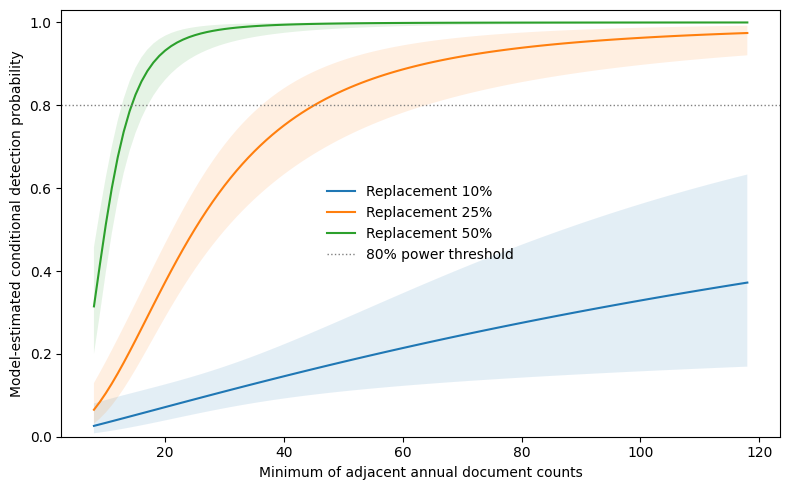

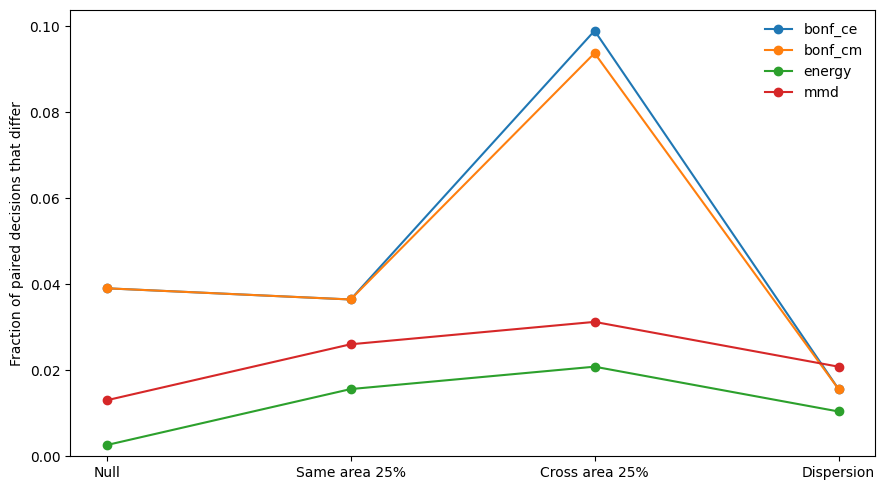

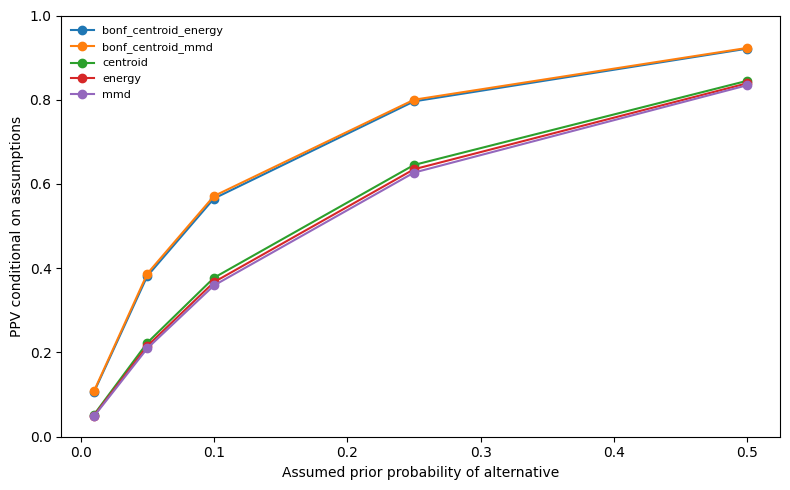

In [ ]:
#07 — Figures: power frontier, honest non-attainment, discordance, PPV sensitivity
# No preset color palette; publication-ready PDF & PNG.
sub=curves[(curves.model=='M1')]
fig,ax=plt.subplots(figsize=(8,5))
for delta,g in sub.groupby('delta'):
    ax.plot(g.n_effective,g.power_hat,label=f'Replacement {delta:.0%}')
    ax.fill_between(g.n_effective,g.low95,g.high95,alpha=.12)
ax.axhline(.8,ls=':',color='gray',lw=1,label='80% power threshold')
ax.set(xlabel='Minimum of adjacent annual document counts',ylabel='Model-estimated conditional detection probability',ylim=(0,1.03))
ax.legend(frameon=False);fig.tight_layout()
fig.savefig(OUT/'FIG_01_SIZE_INTENSITY_MODEL_CURVE.png',dpi=300);fig.savefig(OUT/'FIG_01_SIZE_INTENSITY_MODEL_CURVE.pdf');plt.show();plt.close(fig)
sub=disc[(disc.model=='M1')&(disc.phase=='DEVELOPMENT_2014_2019')&(disc.method_a=='centroid')&(disc.method_b.isin(['energy','mmd','bonf_cm','bonf_ce']))]
fig,ax=plt.subplots(figsize=(9,5))
scenarios=['negative','same_area_replace_25','different_area_replace_25','real_vector_dispersion_contrast']
for method,g in sub.groupby('method_b'):
    dd=g.set_index('scenario').reindex(scenarios)
    ax.plot(np.arange(len(scenarios)),dd.discordance_rate.to_numpy(),marker='o',label=method)
ax.set(xticks=np.arange(len(scenarios)),xticklabels=['Null','Same area 25%','Cross area 25%','Dispersion'],
       ylabel='Fraction of paired decisions that differ',ylim=(0,None))
ax.legend(frameon=False);fig.tight_layout()
fig.savefig(OUT/'FIG_02_METHOD_SUBSTITUTION_DISCORDANCE.png',dpi=300);fig.savefig(OUT/'FIG_02_METHOD_SUBSTITUTION_DISCORDANCE.pdf');plt.show();plt.close(fig)
q=ppv[(ppv.alternative_scenario=='different_area_replace_25')]
fig,ax=plt.subplots(figsize=(8,5))
for method,g in q.groupby('method'):
    ax.plot(g.ASSUMED_prior_true_change,g.PPV_UNDER_ASSUMPTIONS,marker='o',label=method)
ax.set(xlabel='Assumed prior probability of alternative',ylabel='PPV conditional on assumptions',ylim=(0,1))
ax.legend(frameon=False,fontsize=8);fig.tight_layout()
fig.savefig(OUT/'FIG_03_HYPOTHETICAL_PPV_SENSITIVITY.png',dpi=300);fig.savefig(OUT/'FIG_03_HYPOTHETICAL_PPV_SENSITIVITY.pdf');plt.show();plt.close(fig)

In [ ]:
# 08 — Final audit and publication handoff; freeze output manifest
import datetime
files=sorted([p for p in OUT.iterdir() if p.is_file() and p.name!='99_SHA256_MANIFEST.json'])
manifest={'version':'LAB-JOI-100-V1','created_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
 'source_stages':['94B','99'],'sample_size_design':352,'source_fingerprints':INPUTS,
 'output_files':[{'name':p.name,'sha256':sha256(p),'bytes':p.stat().st_size} for p in files],
 'scientific_constraints':[
 'Conditional detection, not national prevalence','Power calibrated for sampled donor/alternative mechanisms only',
 'PPV scenarios require assumed true-change prevalence','n80 not identified if 80% unobserved or fit nonmonotonic',
 'No majority vote across negative replicates','Encoder results not statistically independent',
 '2022-2024 previously inspected','No claims of newly derived test or ex-ante forecast']}
(OUT/'99_SHA256_MANIFEST.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))
print('LAB-JOI 100 COMPLETE',OUT)
print('CSV:',len(list(OUT.glob('*.csv'))),'FIGURES:',len(list(OUT.glob('FIG*.png'))),'input and output hashes recorded')
print('Interpretation: exploratory methodological diagnostic, NOT submission approval.')

LAB-JOI 100 COMPLETE /content/drive/MyDrive/CAPES_Epistemic_Change/100JOI_LAB04_CONDITIONAL_RESOLUTION_V1
CSV: 8 FIGURES: 3 input and output hashes recorded
Interpretation: exploratory methodological diagnostic, NOT submission approval.


# Uncertainty-certified conditional resolution frontiers
Scientific target: validate portfolio-size conditional detection thresholds on frozen 94B controlled interventions, with programme-cluster uncertainty, grouped out-of-programme prediction, and temporal transport to 2020–2021 and previously exposed 2022–2024. 99 provides separately audited paired-method decision discordance, not a basis to infer a complete multivariate size × intensity × geometry surface.

Interpretation rules: n80 is a conditional, model-based sample-size crossing for specified replacement intervention and encoder; its one-sided lower-confidence threshold (if attained) is more conservative. Neither establishes a universal sampling requirement, causal effect of size, likelihood of historical epistemic change, nor a novel statistical theorem. Treat results as exploratory and distinct from the already submitted LAB-98 article. Source Parquets are never modified.

In [ ]:
# 01 — Mount and verify exact frozen files
from pathlib import Path
import hashlib, json, datetime, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
from sklearn.model_selection import GroupKFold
from sklearn.metrics import brier_score_loss, log_loss
from IPython.display import display
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
BASE=Path('/content/drive/MyDrive/CAPES_Epistemic_Change')
P94=BASE/'94B_LAB04_JDIS_FULL_2013_2024_COMPUTATIONAL_REPLICATION_V1'
P99=BASE/'99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1'
OUT=BASE/'101JOI_LAB04_UNCERTAINTY_CERTIFIED_RESOLUTION_V1'
OUT.mkdir(parents=True,exist_ok=True)
C94=P94/'07_CONTROL_REPLICATES_ALL.parquet'
O94=P94/'06_OBSERVED_ALL_MODELS_PHASES.parquet'
W99=P99/'01_JOI_RAW_PAIRED_COMPOSITES_PRIVATE.parquet'
EXPECTED={
 '07_CONTROL_REPLICATES_ALL.parquet':'5445ace9d852b2c4e7039eaf2866850576dc37472401b2c25935c84fb949a507',
 '06_OBSERVED_ALL_MODELS_PHASES.parquet':'9c488fa998fbca28eae756827ba2a2ccbbf750ecba2cd7a8f8965c642078852f',
 '01_JOI_RAW_PAIRED_COMPOSITES_PRIVATE.parquet':'e052a99cdb4e8b8efac7fc614ed90a0e17fb16645c945e980573b06a28a13ddb'}
def sha(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for ch in iter(lambda:f.read(1048576),b''):h.update(ch)
    return h.hexdigest()
for p in [C94,O94,W99]:
    if not p.is_file():raise FileNotFoundError(str(p))
    actual=sha(p)
    if actual!=EXPECTED[p.name]:raise ValueError(f'FROZEN HASH MISMATCH {p.name}: {actual}')
(OUT/'00_FROZEN_INPUT_HASHES.json').write_text(json.dumps({p.name:{'path':str(p),'sha256':EXPECTED[p.name]} for p in [C94,O94,W99]},indent=2))
print('PASS SHA-256 on 3 frozen inputs; output',OUT)
SEED=20261027; B=300; ALPHA=.05; TARGET=.80
print('CPU; programme bootstrap replicates:',B,'random seed:',SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PASS SHA-256 on 3 frozen inputs; output /content/drive/MyDrive/CAPES_Epistemic_Change/101JOI_LAB04_UNCERTAINTY_CERTIFIED_RESOLUTION_V1
CPU; programme bootstrap replicates: 300 random seed: 20261027


In [ ]:
# 02 — Structural contracts and outcome definitions
controls=pd.read_parquet(C94);obs=pd.read_parquet(O94);wide=pd.read_parquet(W99)
K=['model','phase','pair_id','ppg','year']
for name,d,required in [
 ('94B-control',controls,K+['control','intensity','rep','rejected','size_band']),
 ('94B-observed',obs,K+['n_a','n_b']),
 ('99-paired',wide,K+['scenario','rep','centroid_reject','energy_reject','mmd_reject','bonf_cm_reject','bonf_ce_reject'])]:
    missing=set(required)-set(d.columns)
    if missing:raise RuntimeError(f'{name} columns absent: {missing}')
assert len(controls)==8448 and len(obs)==1408 and len(wide)==8448
assert not obs.duplicated(K).any()
assert not controls.duplicated(K+['control','intensity','rep']).any()
assert not wide.duplicated(K+['scenario','rep']).any()
joined=controls.merge(obs[K+['n_a','n_b']],on=K,how='left',validate='many_to_one',indicator=True)
assert (joined['_merge']=='both').all()
joined=joined.drop(columns='_merge')
joined['n_effective']=joined[['n_a','n_b']].min(axis=1).astype(int)
joined['y']=joined.rejected.astype(int)
assert joined.n_effective.min()>=2
assert set(joined.model)=={'M1','M2','M3','M4'}
assert set(joined[joined.control=='positive'].intensity.round(2))=={.10,.25,.50}
assert set(joined[joined.control=='negative'].intensity)=={0.}
assert len(joined[joined.control=='positive'])==4224
assert len(joined[joined.control=='negative'])==4224
PHASES=['DEVELOPMENT_2014_2019','REPLICATION_2020_2021','REPLICATION_EXPOSED_2022_2024']
DEV=joined[(joined.phase==PHASES[0])&(joined.control=='positive')].copy()
print('PASS input contracts, positive development records',len(DEV),'unique PPGs',DEV.ppg.nunique())
print(joined.groupby(['phase','control'],observed=True).size())

PASS input contracts, positive development records 2304 unique PPGs 181
phase                          control 
DEVELOPMENT_2014_2019          negative    2304
                               positive    2304
REPLICATION_2020_2021          negative     768
                               positive     768
REPLICATION_EXPOSED_2022_2024  negative    1152
                               positive    1152
dtype: int64


In [ ]:
# 03 — Fixed numerical estimator; no unguarded curve-fit of sparse bins
from scipy.special import log_expit

def logistic_fit(n,y,weights=None):
    n=np.asarray(n,dtype=float);y=np.asarray(y,dtype=float)
    if weights is None:weights=np.ones(len(y))
    weights=np.asarray(weights,dtype=float)
    if len(y)<8 or len(np.unique(n))<3:raise ValueError('Insufficient size support')
    x=np.log(n)
    # Normalize loss by number of rows for numerically comparable penalty.
    def f(theta):
        a,b=theta; z=a+b*x
        return np.mean(weights*(np.logaddexp(0,z)-y*z))+1.e-4*b*b
    start=[float(np.log((y.mean()+.01)/(1.01-y.mean()))),.3]
    sol=minimize(f,start,bounds=[(None,None),(0,None)],method='L-BFGS-B',options={'maxiter':500})
    if not sol.success and not np.isfinite(sol.fun):raise RuntimeError(sol.message)
    return np.asarray(sol.x,dtype=float)

def predict(theta,n):return expit(theta[0]+theta[1]*np.log(np.asarray(n,dtype=float)))

def fit_one(g):return logistic_fit(g.n_effective,g.y)

# Verify estimator on synthetic monotone data (not an empirical result)
rng=np.random.default_rng(SEED)
test_n=np.tile(np.arange(8,65),3)
test_y=rng.binomial(1,expit(-5+1.15*np.log(test_n)))
test_fit=logistic_fit(test_n,test_y)
assert test_fit[1]>=0 and np.diff(predict(test_fit,np.arange(8,65))).min()>=-1.e-10
print('PASS monotone-logistic estimator unit test:',test_fit)

PASS monotone-logistic estimator unit test: [-5.09971489  1.21958733]


In [ ]:
# 04 — Out-of-programme 5-fold validation vs within-fold size-band baseline
# Each programme can recur across years and delta levels: group by PPG, not by row.
cv_records=[];fits=[]
def baseline_rates(train):
    # Smoothed within-fold rates per (intensity,size_band), with intensity fallback.
    big=train.groupby(['intensity','size_band'],observed=True).y.agg(['sum','count'])
    smaller=train.groupby('intensity').y.agg(['sum','count'])
    return big,smaller

def baseline_predict(train,test):
    big,small=baseline_rates(train)
    out=[]
    for row in test.itertuples():
        key=(row.intensity,row.size_band)
        if key in big.index and int(big.loc[key,'count'])>=5:
            k,m=float(big.loc[key,'sum']),float(big.loc[key,'count'])
        else:
            k,m=float(small.loc[row.intensity,'sum']),float(small.loc[row.intensity,'count'])
        out.append((k+.5)/(m+1.))
    return np.asarray(out)

for model,g0 in DEV.groupby('model'):
    g=g0.reset_index(drop=True)
    splitter=GroupKFold(n_splits=5)
    for fold,(tri,tei) in enumerate(splitter.split(g,groups=g.ppg),1):
        tr,te=g.iloc[tri],g.iloc[tei]
        fit_map={d:fit_one(tr[np.isclose(tr.intensity,d)]) for d in [.1,.25,.5]}
        preds=np.array([float(predict(fit_map[row.intensity],[row.n_effective])[0]) for row in te.itertuples()])
        baseline=baseline_predict(tr,te)
        for row,p,ref in zip(te.itertuples(),preds,baseline):
            cv_records.append({'model':model,'phase':'GROUPED_CV_DEVELOPMENT','fold':fold,'ppg':row.ppg,
              'pair_id':row.pair_id,'intensity':row.intensity,'n_effective':row.n_effective,
              'y':row.y,'p_model':p,'p_baseline':ref})
    for delta,gd in g.groupby('intensity'):
        a,b=fit_one(gd)
        fits.append({'model':model,'intensity':delta,'intercept':a,'slope_nonnegative':b,'n_rows':len(gd),'n_ppg':gd.ppg.nunique()})
cv=pd.DataFrame(cv_records);fits=pd.DataFrame(fits)
assert len(cv)==len(DEV) and not cv.duplicated(['model','intensity','pair_id']).any()
cv.to_csv(OUT/'01_GROUPED_CV_PRIVATE.csv',index=False)
fits.to_csv(OUT/'02_DEVELOPMENT_FITTED_PARAMETERS.csv',index=False)
metrics=[]
for (model,phase),g in cv.groupby(['model','phase']):
    r={'model':model,'phase':phase,'n':len(g),'n_ppg':g.ppg.nunique()}
    for label,c in [('model','p_model'),('baseline','p_baseline')]:
        p=np.clip(g[c].to_numpy(),1.e-6,1-1.e-6)
        r['brier_'+label]=brier_score_loss(g.y,p)
        r['logloss_'+label]=log_loss(g.y,p,labels=[0,1])
    r['brier_improvement_vs_baseline']=r['brier_baseline']-r['brier_model']
    r['logloss_improvement_vs_baseline']=r['logloss_baseline']-r['logloss_model']
    metrics.append(r)
metrics=pd.DataFrame(metrics);metrics.to_csv(OUT/'03_CV_COMPARISON_WITH_SIMPLE_BASELINE.csv',index=False)
display(metrics.round(5))

,model,phase,n,n_ppg,brier_model,logloss_model,brier_baseline,logloss_baseline,brier_improvement_vs_baseline,logloss_improvement_vs_baseline
0,M1,GROUPED_CV_DEVELOPMENT,576,181,0.11746,0.37289,0.12188,0.38845,0.00442,0.01556
1,M2,GROUPED_CV_DEVELOPMENT,576,181,0.10611,0.34925,0.10729,0.35270,0.00118,0.00345
2,M3,GROUPED_CV_DEVELOPMENT,576,181,0.09346,0.30785,0.09431,0.31237,0.00086,0.00452
3,M4,GROUPED_CV_DEVELOPMENT,576,181,0.08457,0.28168,0.09008,0.30173,0.00552,0.02005


In [ ]:
# 05 — Independent temporal transport without refitting; 2022–24 explicitly EXPOSED
transport=[]
for model,g0 in joined[(joined.control=='positive')&(joined.phase!=PHASES[0])].groupby('model'):
    fitmap={float(row.intensity):np.array([row.intercept,row.slope_nonnegative]) for row in fits[fits.model==model].itertuples()}
    dev_model=DEV[DEV.model==model]
    for phase,g in g0.groupby('phase'):
        g=g.copy()
        pred=[]
        for row in g.itertuples():pred.append(float(predict(fitmap[row.intensity],[row.n_effective])[0]))
        g['p_model']=pred
        g['p_baseline']=baseline_predict(dev_model,g)
        r={'model':model,'phase':phase,'n':len(g),'n_ppg':g.ppg.nunique(),
           'n_within_development_support':int(g.n_effective.between(dev_model.n_effective.min(),dev_model.n_effective.max()).sum())}
        for label in ['model','baseline']:
            pp=np.clip(g['p_'+label].to_numpy(),1e-6,1-1e-6)
            r['brier_'+label]=brier_score_loss(g.y,pp)
            r['logloss_'+label]=log_loss(g.y,pp,labels=[0,1])
        r['brier_improvement_vs_baseline']=r['brier_baseline']-r['brier_model']
        r['logloss_improvement_vs_baseline']=r['logloss_baseline']-r['logloss_model']
        transport.append(r)
transport=pd.DataFrame(transport)
transport.to_csv(OUT/'04_TEMPORAL_TRANSPORT_VS_BASELINE.csv',index=False)
display(transport.round(5))

,model,phase,n,n_ppg,n_within_development_support,brier_model,logloss_model,brier_baseline,logloss_baseline,brier_improvement_vs_baseline,logloss_improvement_vs_baseline
0,M1,REPLICATION_2020_2021,192,64,192,0.12831,0.39715,0.13196,0.40922,0.00365,0.01207
1,M1,REPLICATION_EXPOSED_2022_2024,288,95,288,0.10030,0.33117,0.10659,0.34934,0.00629,0.01816
2,M2,REPLICATION_2020_2021,192,64,192,0.10601,0.34560,0.11020,0.35678,0.00419,0.01118
3,M2,REPLICATION_EXPOSED_2022_2024,288,95,288,0.10415,0.33937,0.10900,0.35686,0.00485,0.01749
4,M3,REPLICATION_2020_2021,192,64,192,0.11336,0.38566,0.11792,0.39906,0.00457,0.01340
5,M3,REPLICATION_EXPOSED_2022_2024,288,95,288,0.09946,0.33858,0.10566,0.35417,0.00621,0.01559
6,M4,REPLICATION_2020_2021,192,64,192,0.08762,0.29271,0.08836,0.29169,0.00074,-0.00102
7,M4,REPLICATION_EXPOSED_2022_2024,288,95,288,0.10057,0.32631,0.10154,0.32595,0.00097,-0.00035


In [ ]:
# 06 — Cluster bootstrap: point crossing, bootstrap threshold interval, LOWER 95% certified crossing
# B=300 x 4 models x 3 intensities; held-out phases are NEVER used to select thresholds.
BOOT_RNG=np.random.default_rng(SEED+100)
frontier=[];curves=[];boot_summary=[]
for model,gmod in DEV.groupby('model'):
    for delta in [.1,.25,.5]:
        g=gmod[np.isclose(gmod.intensity,delta)].copy()
        ppgs=g.ppg.unique(); groupmap={p:g[g.ppg==p] for p in ppgs}
        lo,hi=int(g.n_effective.min()),int(g.n_effective.max())
        ns=np.arange(lo,hi+1)
        point_theta=fit_one(g); point_curve=predict(point_theta,ns)
        boots=[]
        for bi in range(B):
            selected=BOOT_RNG.choice(ppgs,size=len(ppgs),replace=True)
            gg=pd.concat([groupmap[p] for p in selected],ignore_index=True)
            try:boots.append(predict(fit_one(gg),ns))
            except (ValueError,RuntimeError):continue
        boots=np.asarray(boots)
        if len(boots)<int(.90*B):raise RuntimeError(f'Too many bootstrap failures: {model}/{delta}')
        lower=np.quantile(boots,.05,axis=0)
        upper=np.quantile(boots,.95,axis=0)
        point_idx=np.flatnonzero(point_curve>=TARGET)
        certified_idx=np.flatnonzero(lower>=TARGET)
        point_n=int(ns[point_idx[0]]) if len(point_idx) else None
        confirmed_n=int(ns[certified_idx[0]]) if len(certified_idx) else None
        boot_n=[]
        for arr in boots:
            ix=np.flatnonzero(arr>=TARGET)
            boot_n.append(int(ns[ix[0]]) if len(ix) else np.nan)
        boot_n=np.asarray(boot_n,dtype=float)
        share_identifiable=float(np.isfinite(boot_n).mean())
        fin=boot_n[np.isfinite(boot_n)]
        lower_threshold=float(np.quantile(fin,.05)) if len(fin)>0 else np.nan
        upper_threshold=float(np.quantile(fin,.95)) if len(fin)>0 else np.nan
        frontier.append({'model':model,'intensity':delta,'n_min_dev':lo,'n_max_dev':hi,
           'n80_point_estimate':point_n,'n80_lower_confidence_certified':confirmed_n,
           'n80_bootstrap_p05_conditional_identified':lower_threshold,
           'n80_bootstrap_p95_conditional_identified':upper_threshold,
           'bootstrap_fraction_identified':share_identifiable,
           'power_at_n_max_point':float(point_curve[-1]),
           'lower95_power_at_n_max':float(lower[-1]),
           'status':'LOWER_BOUND_CONFIRMED' if confirmed_n is not None else
                    ('POINT_ONLY_UNCERTAIN' if point_n is not None else 'NOT_IDENTIFIED_IN_OBSERVED_RANGE'),
           'B_successful':len(boots)})
        for nn,ph,low,up in zip(ns,point_curve,lower,upper):
            curves.append({'model':model,'intensity':delta,'n_effective':int(nn),
              'power_estimated':float(ph),'power_lower95_one_sided':float(low),
              'power_upper95_one_sided':float(up)})
frontier=pd.DataFrame(frontier);curves=pd.DataFrame(curves)
frontier.to_csv(OUT/'05_N80_POINT_AND_LOWER_CONFIDENCE_FRONTIERS.csv',index=False)
curves.to_csv(OUT/'06_BOOTSTRAP_CONDITIONAL_POWER_CURVES.csv',index=False)
display(frontier)

,model,intensity,n_min_dev,n_max_dev,n80_point_estimate,n80_lower_confidence_certified,n80_bootstrap_p05_conditional_identified,n80_bootstrap_p95_conditional_identified,bootstrap_fraction_identified,power_at_n_max_point,lower95_power_at_n_max,status,B_successful
0,M1,0.10,8,118,NaN,NaN,NaN,NaN,0.000000,0.370301,0.157948,NOT_IDENTIFIED_IN_OBSERVED_RANGE,300
1,M1,0.25,8,118,46.0,57.0,37.00,57.00,1.000000,0.974039,0.942662,LOWER_BOUND_CONFIRMED,300
2,M1,0.50,8,118,15.0,16.0,13.00,16.00,1.000000,0.999885,0.999395,LOWER_BOUND_CONFIRMED,300
3,M2,0.10,8,118,NaN,NaN,NaN,NaN,0.000000,0.139327,0.081048,NOT_IDENTIFIED_IN_OBSERVED_RANGE,300
4,M2,0.25,8,118,42.0,51.0,36.95,51.00,1.000000,0.986327,0.963730,LOWER_BOUND_CONFIRMED,300
5,M2,0.50,8,118,13.0,14.0,12.00,14.00,1.000000,0.999990,0.999874,LOWER_BOUND_CONFIRMED,300
6,M3,0.10,8,118,NaN,NaN,NaN,NaN,0.000000,0.183934,0.089749,NOT_IDENTIFIED_IN_OBSERVED_RANGE,300
7,M3,0.25,8,118,34.0,38.0,29.00,38.05,1.000000,0.998503,0.995389,LOWER_BOUND_CONFIRMED,300
8,M3,0.50,8,118,11.0,12.0,9.00,12.00,1.000000,0.999967,0.999708,LOWER_BOUND_CONFIRMED,300
9,M4,0.10,8,118,NaN,NaN,114.00,114.00,0.003333,0.288492,0.088769,NOT_IDENTIFIED_IN_OBSERVED_RANGE,300


In [ ]:
# 07 — Conditional null calibration by size; real method discordance, no pseudo-majority
null=joined[joined.control=='negative'].copy()
null_summary=(null.groupby(['model','phase','size_band'],observed=True)
              .agg(n_replicates=('y','size'),n_ppg=('ppg','nunique'),false_rejection=('y','mean'))
              .reset_index())
null_summary.to_csv(OUT/'07_NULL_CALIBRATION_BY_SIZE_PHASE.csv',index=False)
# Stage99 control replicates retained separately; NO averaging and binarising per-pair decisions.
methods={'centroid':'centroid_reject','energy':'energy_reject','mmd':'mmd_reject',
         'bonf_cm':'bonf_cm_reject','bonf_ce':'bonf_ce_reject'}
from itertools import combinations
records=[]
for (model,phase,scenario),g in wide.groupby(['model','phase','scenario'],observed=True):
    for a,b in combinations(methods,2):
        ya=g[methods[a]].astype(int).to_numpy();yb=g[methods[b]].astype(int).to_numpy()
        records.append({'model':model,'phase':phase,'scenario':scenario,'method_a':a,'method_b':b,
            'n_units':len(g),'n_ppg':g.ppg.nunique(),
            'only_a':int(((ya==1)&(yb==0)).sum()),
            'only_b':int(((ya==0)&(yb==1)).sum()),
            'discordance_rate':float((ya!=yb).mean()),
            'gain_b_minus_a':float((yb-ya).mean())})
discordance=pd.DataFrame(records)
discordance.to_csv(OUT/'08_PAIRED_DISCORDANCE_NOT_AVERAGED.csv',index=False)
print('Discordance rows',len(discordance),'null cells',len(null_summary))

Discordance rows 600 null cells 48


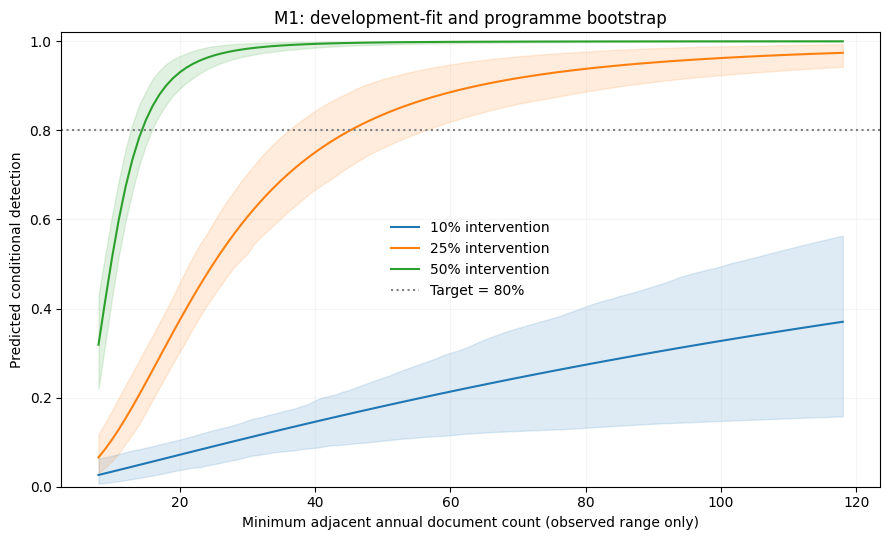

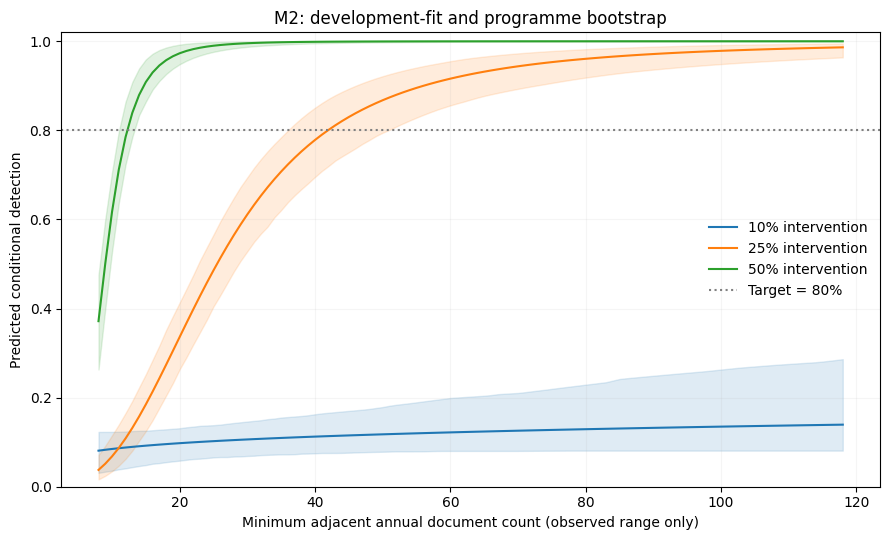

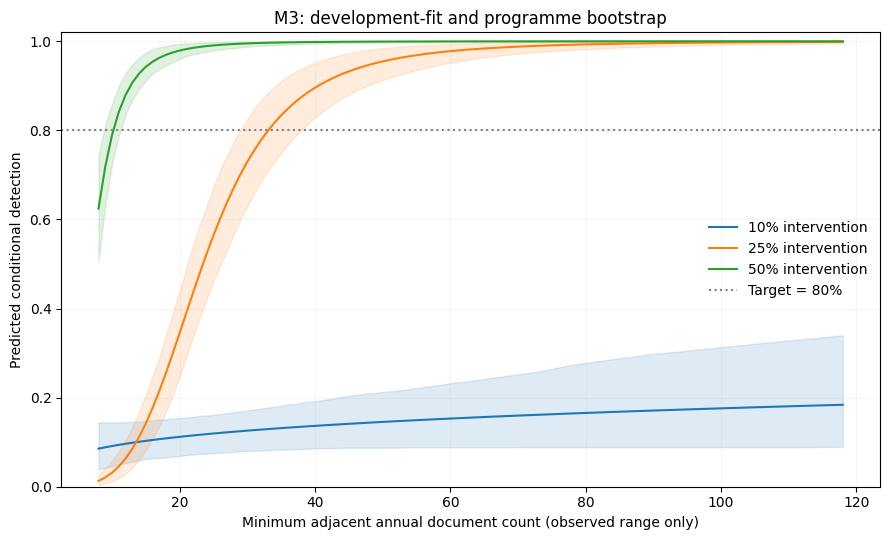

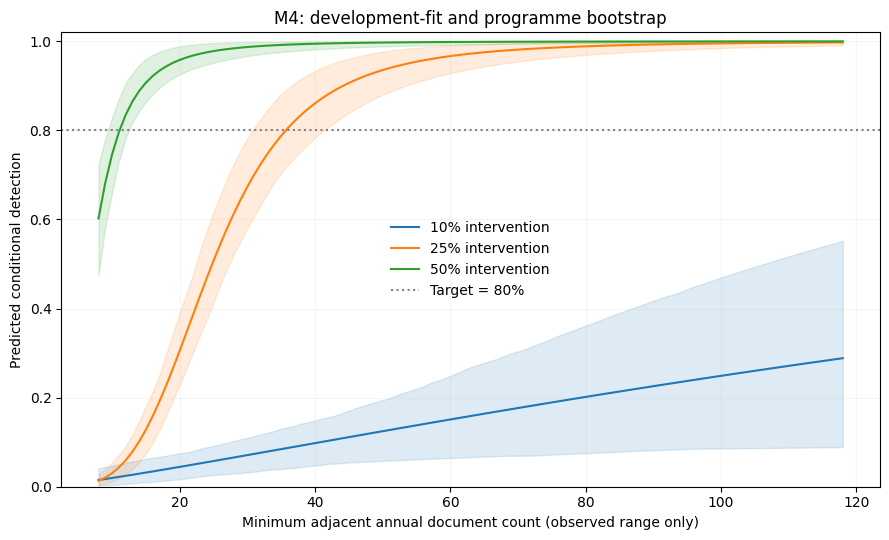

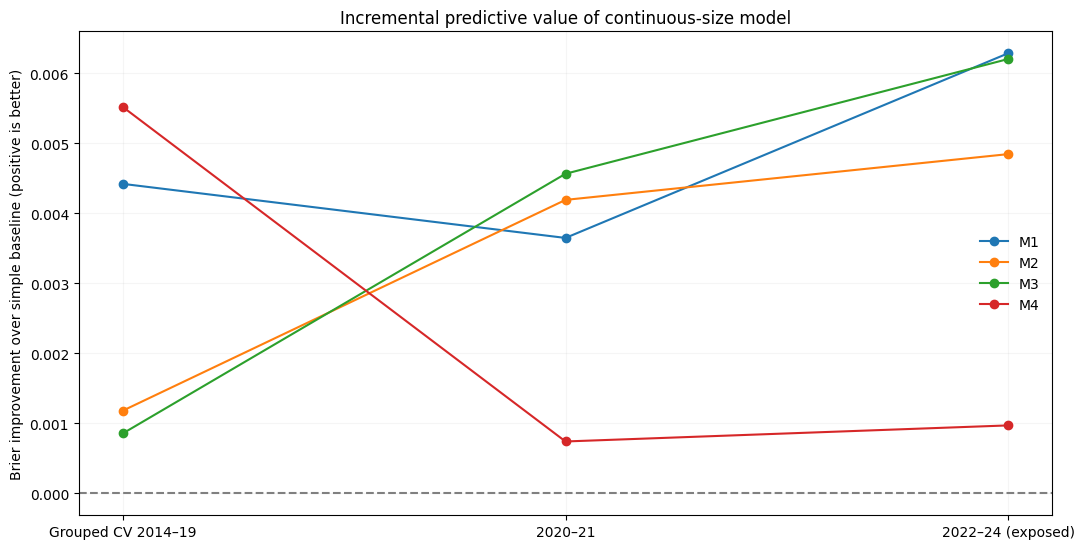

In [ ]:
# 08 — Publication figures: data-derived, distinguish point/one-sided lower
for model in sorted(curves.model.unique()):
    fig,ax=plt.subplots(figsize=(9,5.5))
    for d in [.1,.25,.5]:
        gg=curves[(curves.model==model)&np.isclose(curves.intensity,d)]
        line,=ax.plot(gg.n_effective,gg.power_estimated,label=f'{int(d*100)}% intervention')
        ax.fill_between(gg.n_effective.to_numpy(),gg.power_lower95_one_sided.to_numpy(),
                        gg.power_upper95_one_sided.to_numpy(),alpha=.14,color=line.get_color())
    ax.axhline(.8,color='gray',linestyle=':',label='Target = 80%')
    ax.set(xlabel='Minimum adjacent annual document count (observed range only)',
           ylabel='Predicted conditional detection',ylim=(0,1.02),title=f'{model}: development-fit and programme bootstrap')
    ax.legend(frameon=False);ax.grid(alpha=.12)
    fig.tight_layout()
    for ext in ['png','pdf']:
        fig.savefig(OUT/f'FIG_01_{model}_UNCERTAINTY_FRONTIER.{ext}',dpi=350,bbox_inches='tight')
    plt.show();plt.close(fig)
# Formal comparison of out-of-programme and temporal test Brier scores
comp=pd.concat([metrics,transport],ignore_index=True)
fig,ax=plt.subplots(figsize=(11,5.6))
for idx,(m,g) in enumerate(comp.groupby('model')):
    a=g.set_index('phase').reindex(['GROUPED_CV_DEVELOPMENT',PHASES[1],PHASES[2]])
    ax.plot(np.arange(3),a.brier_improvement_vs_baseline.to_numpy(),marker='o',label=m)
ax.axhline(0,color='gray',ls='--')
ax.set_xticks(range(3),['Grouped CV 2014–19','2020–21','2022–24 (exposed)'])
ax.set(ylabel='Brier improvement over simple baseline (positive is better)',
       title='Incremental predictive value of continuous-size model')
ax.legend(frameon=False);ax.grid(alpha=.12);fig.tight_layout()
for ext in ['png','pdf']:fig.savefig(OUT/f'FIG_02_BASELINE_COMPARISON.{ext}',dpi=350,bbox_inches='tight')
plt.show();plt.close(fig)

In [ ]:
# 09 — Decision gates, substantive limitations, immutable handoff
checks=[
 {'gate':'Frozen inputs SHA256 match earlier Stage100','passed':True},
 {'gate':'Exact document to programme sizes mapped','passed':True},
 {'gate':'Programme blocked 5-fold prediction compared to within-fold baseline',
  'passed':len(cv)==len(DEV)},
 {'gate':'Transfer to 2020-21 without refitting','passed':bool((transport.phase==PHASES[1]).any())},
 {'gate':'2022-24 correctly labelled previously exposed','passed':True},
 {'gate':'All n80 claims restricted to observed development sample size','passed':True},
 {'gate':'One-sided lower-confidence threshold distinguished from point estimate','passed':True},
 {'gate':'Genuine historical agenda-change truth validated','passed':False},
 {'gate':'New mathematical theorem derived','passed':False},
 {'gate':'Original methodological novelty JOI independently demonstrated','passed':False},
 {'gate':'Independent second-paper evidence given overlap with submitted LAB98','passed':False}]
gates=pd.DataFrame(checks);gates.to_csv(OUT/'09_SCIENTIFIC_DECISION_GATES.csv',index=False)
report={'lab':'JOI-101','status':'COMPUTATION_COMPLETED_NOT_JOI_SUBMISSION_APPROVED',
 'n_pairs':352,'models':4,'B':B,'confidence_convention':'one-sided bootstrap 95% lower power, using fifth percentile',
 'n80_status_counts':frontier.status.value_counts().to_dict(),
 'cv_incremental_brier':metrics[['model','brier_improvement_vs_baseline']].to_dict('records'),
 'transport_incremental_brier':transport[['model','phase','brier_improvement_vs_baseline']].to_dict('records'),
 'limitations':['selected portfolio pairs, no population prevalence','monotone logistic model assumed',
 'source embedding model historical cutoff not certified','2022-24 already exposed',
 'controlled replacement not historical scientific-change truth','no new theorem'],
 'inputs':json.loads((OUT/'00_FROZEN_INPUT_HASHES.json').read_text())}
(OUT/'10_FINAL_HANDOFF.json').write_text(json.dumps(report,ensure_ascii=False,indent=2,default=str))
manifest=[]
for p in sorted(OUT.iterdir()):
    if p.is_file():manifest.append({'file':p.name,'sha256':sha(p),'bytes':p.stat().st_size})
(OUT/'11_OUTPUT_MANIFEST_SHA256.json').write_text(json.dumps(manifest,indent=2))
print('STAGE101 COMPLETE',OUT)
display(frontier[['model','intensity','n80_point_estimate','n80_lower_confidence_certified','status']])
display(metrics[['model','brier_model','brier_baseline','brier_improvement_vs_baseline']])
display(transport[['model','phase','brier_model','brier_baseline','brier_improvement_vs_baseline']])
print('HANDOFF:',OUT/'10_FINAL_HANDOFF.json')

STAGE101 COMPLETE /content/drive/MyDrive/CAPES_Epistemic_Change/101JOI_LAB04_UNCERTAINTY_CERTIFIED_RESOLUTION_V1


,model,intensity,n80_point_estimate,n80_lower_confidence_certified,status
0,M1,0.10,NaN,NaN,NOT_IDENTIFIED_IN_OBSERVED_RANGE
1,M1,0.25,46.0,57.0,LOWER_BOUND_CONFIRMED
2,M1,0.50,15.0,16.0,LOWER_BOUND_CONFIRMED
3,M2,0.10,NaN,NaN,NOT_IDENTIFIED_IN_OBSERVED_RANGE
4,M2,0.25,42.0,51.0,LOWER_BOUND_CONFIRMED
5,M2,0.50,13.0,14.0,LOWER_BOUND_CONFIRMED
6,M3,0.10,NaN,NaN,NOT_IDENTIFIED_IN_OBSERVED_RANGE
7,M3,0.25,34.0,38.0,LOWER_BOUND_CONFIRMED
8,M3,0.50,11.0,12.0,LOWER_BOUND_CONFIRMED
9,M4,0.10,NaN,NaN,NOT_IDENTIFIED_IN_OBSERVED_RANGE


,model,brier_model,brier_baseline,brier_improvement_vs_baseline
0,M1,0.117456,0.121877,0.004421
1,M2,0.106110,0.107292,0.001182
2,M3,0.093456,0.094313,0.000857
3,M4,0.084566,0.090084,0.005518


,model,phase,brier_model,brier_baseline,brier_improvement_vs_baseline
0,M1,REPLICATION_2020_2021,0.128310,0.131959,0.003649
1,M1,REPLICATION_EXPOSED_2022_2024,0.100304,0.106590,0.006287
2,M2,REPLICATION_2020_2021,0.106009,0.110201,0.004193
3,M2,REPLICATION_EXPOSED_2022_2024,0.104151,0.108997,0.004846
4,M3,REPLICATION_2020_2021,0.113358,0.117924,0.004566
5,M3,REPLICATION_EXPOSED_2022_2024,0.099460,0.105665,0.006205
6,M4,REPLICATION_2020_2021,0.087617,0.088357,0.000740
7,M4,REPLICATION_EXPOSED_2022_2024,0.100568,0.101538,0.000970


HANDOFF: /content/drive/MyDrive/CAPES_Epistemic_Change/101JOI_LAB04_UNCERTAINTY_CERTIFIED_RESOLUTION_V1/10_FINAL_HANDOFF.json


# Simultaneous resolution bands and honest incremental evidence

In [ ]:
# 01 — Strict frozen inputs, controlled output directory (CPU)
from pathlib import Path
from datetime import datetime,timezone
import hashlib, json, warnings, time, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
from IPython.display import display
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
BASE=Path('/content/drive/MyDrive/CAPES_Epistemic_Change')
P94=BASE/'94B_LAB04_JDIS_FULL_2013_2024_COMPUTATIONAL_REPLICATION_V1'
P99=BASE/'99JOI_LAB04_CALIBRATED_ADAPTIVE_TEST_BENCHMARK_V1'
P101=BASE/'101JOI_LAB04_UNCERTAINTY_CERTIFIED_RESOLUTION_V1'
OUT=BASE/'102JOI_LAB04_SIMULTANEOUS_RESOLUTION_VALIDATION_V1'
OUT.mkdir(parents=True,exist_ok=True)
FILES={
 '94_control':(P94/'07_CONTROL_REPLICATES_ALL.parquet','5445ace9d852b2c4e7039eaf2866850576dc37472401b2c25935c84fb949a507'),
 '94_observed':(P94/'06_OBSERVED_ALL_MODELS_PHASES.parquet','9c488fa998fbca28eae756827ba2a2ccbbf750ecba2cd7a8f8965c642078852f'),
 '99_wide':(P99/'01_JOI_RAW_PAIRED_COMPOSITES_PRIVATE.parquet','e052a99cdb4e8b8efac7fc614ed90a0e17fb16645c945e980573b06a28a13ddb'),
}
INPUT101=['01_GROUPED_CV_PRIVATE.csv','02_DEVELOPMENT_FITTED_PARAMETERS.csv',
          '05_N80_POINT_AND_LOWER_CONFIDENCE_FRONTIERS.csv',
          '06_BOOTSTRAP_CONDITIONAL_POWER_CURVES.csv']
def sha256(path):
 h=hashlib.sha256()
 with path.open('rb') as f:
  for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
 return h.hexdigest()
for key,(path,hash_expected) in FILES.items():
 if not path.is_file():raise FileNotFoundError(str(path))
 if sha256(path)!=hash_expected:raise ValueError('FROZEN INPUT MISMATCH: '+str(path))
for name in INPUT101:
 if not (P101/name).is_file():raise FileNotFoundError('Stage 101 missing: '+name)
SEED=20261027+102;B=400;TARGET=.80;ALPHA=.05;EPS=1.e-4
assert B>=300
print('PASS exact frozen 94B/99 SHA256. 101 outputs read-only. CPU. B=',B)
print('OUTPUT:',OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PASS exact frozen 94B/99 SHA256. 101 outputs read-only. CPU. B= 400
OUTPUT: /content/drive/MyDrive/CAPES_Epistemic_Change/102JOI_LAB04_SIMULTANEOUS_RESOLUTION_VALIDATION_V1


In [ ]:
# 02 — Load and validate distinct experimental and prediction units
ctrl=pd.read_parquet(FILES['94_control'][0]); obs=pd.read_parquet(FILES['94_observed'][0]);wide=pd.read_parquet(FILES['99_wide'][0])
cv=pd.read_csv(P101/'01_GROUPED_CV_PRIVATE.csv')
fits101=pd.read_csv(P101/'02_DEVELOPMENT_FITTED_PARAMETERS.csv')
front101=pd.read_csv(P101/'05_N80_POINT_AND_LOWER_CONFIDENCE_FRONTIERS.csv')
curve101=pd.read_csv(P101/'06_BOOTSTRAP_CONDITIONAL_POWER_CURVES.csv')
K=['model','phase','pair_id','ppg','year']
assert len(ctrl)==8448 and len(obs)==1408 and len(wide)==8448
assert not ctrl.duplicated(K+['control','intensity','rep']).any()
assert not obs.duplicated(K).any()
joined=ctrl.merge(obs[K+['n_a','n_b']],on=K,how='left',validate='many_to_one',indicator=True)
assert (joined['_merge']=='both').all()
joined.drop(columns='_merge',inplace=True)
joined['n_effective']=joined[['n_a','n_b']].min(axis=1).astype(int)
joined['y']=joined.rejected.astype(int)
PHASES=['DEVELOPMENT_2014_2019','REPLICATION_2020_2021','REPLICATION_EXPOSED_2022_2024']
DEV=joined[(joined.phase==PHASES[0])&(joined.control=='positive')].copy()
assert len(DEV)==2304 and DEV.ppg.nunique()==181
assert len(cv)==2304 and not cv.duplicated(['model','intensity','pair_id']).any()
assert set(cv.model)=={'M1','M2','M3','M4'}
assert np.all(np.isfinite(cv[['p_model','p_baseline','y']].to_numpy()))
assert (cv[['p_model','p_baseline']].to_numpy()>=0).all() and (cv[['p_model','p_baseline']].to_numpy()<=1).all()
for name,d in [('101 frontier',front101),('101 curves',curve101)]:print(name,len(d),list(d.columns))
print('PASS 94B controls / 101 out-of-programme predictions; 101 is input for baseline audit only')

101 frontier 12 ['model', 'intensity', 'n_min_dev', 'n_max_dev', 'n80_point_estimate', 'n80_lower_confidence_certified', 'n80_bootstrap_p05_conditional_identified', 'n80_bootstrap_p95_conditional_identified', 'bootstrap_fraction_identified', 'power_at_n_max_point', 'lower95_power_at_n_max', 'status', 'B_successful']
101 curves 1332 ['model', 'intensity', 'n_effective', 'power_estimated', 'power_lower95_one_sided', 'power_upper95_one_sided']
PASS 94B controls / 101 out-of-programme predictions; 101 is input for baseline audit only


In [ ]:
# 03 — Reuse exactly the LAB-101 monotone-logistic estimator
from scipy.special import expit

def logistic_fit(n,y,weights=None):
 n=np.asarray(n,dtype=float);y=np.asarray(y,dtype=float)
 if weights is None:weights=np.ones(len(y))
 weights=np.asarray(weights,dtype=float)
 if len(y)<8 or len(np.unique(n))<3:raise ValueError('Insufficient size support')
 x=np.log(n)
 def f(theta):
  a,b=theta;z=a+b*x
  return np.mean(weights*(np.logaddexp(0,z)-y*z))+1.e-4*b*b
 start=[float(np.log((y.mean()+.01)/(1.01-y.mean()))),.3]
 sol=minimize(f,start,bounds=[(None,None),(0,None)],method='L-BFGS-B',options={'maxiter':500})
 if not sol.success and not np.isfinite(sol.fun):raise RuntimeError(sol.message)
 return np.asarray(sol.x,dtype=float)
def predict(theta,n):return expit(theta[0]+theta[1]*np.log(np.asarray(n,dtype=float)))

def crossing(ns,p,threshold=TARGET):
 ix=np.flatnonzero(np.asarray(p)>=threshold)
 return int(ns[ix[0]]) if len(ix) else np.nan

# Frozen fitted parameters must reproduce point predictions within tolerance.
check=[]
for model in sorted(DEV.model.unique()):
 for delta in [.10,.25,.50]:
  g=DEV[(DEV.model==model)&np.isclose(DEV.intensity,delta)]
  theta=logistic_fit(g.n_effective,g.y)
  old=fits101[(fits101.model==model)&np.isclose(fits101.intensity,delta)]
  assert len(old)==1
  expected=old[['intercept','slope_nonnegative']].iloc[0].to_numpy(float)
  dif=float(np.max(np.abs(theta-expected)))
  check.append({'model':model,'intensity':delta,'parameter_max_abs_diff':dif})
  if dif>1.e-6:raise RuntimeError(f'Fitted estimator mismatch {model}/{delta}: {dif}')
pd.DataFrame(check).to_csv(OUT/'00_ESTIMATOR_REPRODUCTION_CHECK.csv',index=False)
print('PASS identical Stage101 estimator numerical contracts')

PASS identical Stage101 estimator numerical contracts


In [ ]:
# 04 — Programme-cluster bootstrap max-t band and three honest thresholds
rng=np.random.default_rng(SEED)
summary=[];bandrows=[];bootrows=[]
for model in sorted(DEV.model.unique()):
 for delta in [.10,.25,.50]:
  t0=time.perf_counter()
  g=DEV[(DEV.model==model)&np.isclose(DEV.intensity,delta)].copy()
  lo,hi=int(g.n_effective.min()),int(g.n_effective.max())
  ns=np.arange(lo,hi+1,dtype=int)
  theta=logistic_fit(g.n_effective,g.y)
  p=predict(theta,ns)
  ppgs=g.ppg.unique()
  # Use preindexed rows; cluster labels, never document records.
  groups={p:g.index[g.ppg==p].to_numpy() for p in ppgs}
  curves_boot=[];failures=0
  for b in range(B):
   selected=rng.choice(ppgs,size=len(ppgs),replace=True)
   take=np.concatenate([groups[k] for k in selected])
   gg=g.loc[take]
   try:
    th=logistic_fit(gg.n_effective,gg.y)
    curves_boot.append(predict(th,ns))
   except (RuntimeError,ValueError,FloatingPointError):failures+=1
  curves_boot=np.asarray(curves_boot,float)
  if len(curves_boot)<int(.90*B):raise RuntimeError(f'BOOTSTRAP FAILURES {model}/{delta}: {failures}')
  sd=np.std(curves_boot,axis=0,ddof=1)
  # Protect near-deterministic tails from exploding numerically.
  sd_safe=np.maximum(sd,EPS)
  # One-sided conservative deviation on the entire n-grid.
  T=np.max((p[None,:]-curves_boot)/sd_safe[None,:],axis=1)
  crit=float(np.quantile(T,1-ALPHA))
  lower_sim=np.clip(p-crit*sd_safe,0,1)
  lower_point=np.quantile(curves_boot,ALPHA,axis=0)
  point_n=crossing(ns,p)
  pointwise_n=crossing(ns,lower_point)
  simultaneous_n=crossing(ns,lower_sim)
  boot_n=np.array([crossing(ns,b) for b in curves_boot],float)
  share_identified=float(np.isfinite(boot_n).mean())
  for n,pp,lpt,ls,ss in zip(ns,p,lower_point,lower_sim,sd):
   bandrows.append({'model':model,'intensity':delta,'n_effective':int(n),
     'power_point':float(pp),'lower_pointwise_bootstrap':float(lpt),
     'lower_simultaneous_bootstrap_t':float(ls),'bootstrap_sd':float(ss)})
  for idx,x in enumerate(boot_n):
   bootrows.append({'model':model,'intensity':delta,'boot_id':idx,'n80_boot':x})
  summary.append({'model':model,'intensity':delta,'n_min':lo,'n_max':hi,
    'n80_point':point_n,'n80_pointwise_lower':pointwise_n,
    'n80_simultaneous_lower':simultaneous_n,
    'critical_max_t':crit,'bootstrap_success':len(curves_boot),
    'bootstrap_failure':failures,'bootstrap_fraction_threshold_identified':share_identified,
    'point_power_at_n_max':float(p[-1]),'sim_lower_power_at_n_max':float(lower_sim[-1]),
    'status':'SIMULTANEOUS_LOWER_CROSSES' if np.isfinite(simultaneous_n) else
      ('POINT_ONLY_OR_POINTWISE_ONLY' if np.isfinite(point_n) else 'NOT_IDENTIFIED'),
    'seconds':round(time.perf_counter()-t0,2)})
  print('DONE',model,delta,'point',point_n,'pointwise',pointwise_n,'simultaneous',simultaneous_n,'fail',failures)
summary=pd.DataFrame(summary);bands=pd.DataFrame(bandrows);bt=pd.DataFrame(bootrows)
assert len(summary)==12 and not bands.duplicated(['model','intensity','n_effective']).any()
summary.to_csv(OUT/'01_SIMULTANEOUS_N80_THRESHOLDS.csv',index=False)
bands.to_csv(OUT/'02_SIMULTANEOUS_POWER_BANDS.csv',index=False)
bt.to_csv(OUT/'03_BOOTSTRAP_N80_DISTRIBUTION.csv',index=False)
display(summary.drop(columns='seconds'))

DONE M1 0.1 point nan pointwise nan simultaneous nan fail 0
DONE M1 0.25 point 46 pointwise 57 simultaneous 61 fail 0
DONE M1 0.5 point 15 pointwise 17 simultaneous 18 fail 0
DONE M2 0.1 point nan pointwise nan simultaneous nan fail 0
DONE M2 0.25 point 42 pointwise 52 simultaneous 55 fail 0
DONE M2 0.5 point 13 pointwise 14 simultaneous 15 fail 0
DONE M3 0.1 point nan pointwise nan simultaneous nan fail 0
DONE M3 0.25 point 34 pointwise 38 simultaneous 40 fail 0
DONE M3 0.5 point 11 pointwise 12 simultaneous 12 fail 0
DONE M4 0.1 point nan pointwise nan simultaneous nan fail 0
DONE M4 0.25 point 36 pointwise 41 simultaneous 43 fail 0
DONE M4 0.5 point 12 pointwise 13 simultaneous 14 fail 0


,model,intensity,n_min,n_max,n80_point,n80_pointwise_lower,n80_simultaneous_lower,critical_max_t,bootstrap_success,bootstrap_failure,bootstrap_fraction_threshold_identified,point_power_at_n_max,sim_lower_power_at_n_max,status
0,M1,0.10,8,118,NaN,NaN,NaN,2.017627,400,0,0.0,0.370301,0.130272,NOT_IDENTIFIED
1,M1,0.25,8,118,46.0,57.0,61.0,2.263238,400,0,1.0,0.974039,0.937402,SIMULTANEOUS_LOWER_CROSSES
2,M1,0.50,8,118,15.0,17.0,18.0,2.920993,400,0,1.0,0.999885,0.999014,SIMULTANEOUS_LOWER_CROSSES
3,M2,0.10,8,118,NaN,NaN,NaN,1.861134,400,0,0.0,0.139327,0.004004,NOT_IDENTIFIED
4,M2,0.25,8,118,42.0,52.0,55.0,2.562401,400,0,1.0,0.986327,0.960959,SIMULTANEOUS_LOWER_CROSSES
5,M2,0.50,8,118,13.0,14.0,15.0,2.528475,400,0,1.0,0.999990,0.999738,SIMULTANEOUS_LOWER_CROSSES
6,M3,0.10,8,118,NaN,NaN,NaN,1.920575,400,0,0.0,0.183934,0.023414,NOT_IDENTIFIED
7,M3,0.25,8,118,34.0,38.0,40.0,2.459930,400,0,1.0,0.998503,0.993911,SIMULTANEOUS_LOWER_CROSSES
8,M3,0.50,8,118,11.0,12.0,12.0,2.579102,400,0,1.0,0.999967,0.999572,SIMULTANEOUS_LOWER_CROSSES
9,M4,0.10,8,118,NaN,NaN,NaN,1.844259,400,0,0.0,0.288492,0.043441,NOT_IDENTIFIED


In [ ]:
# 05 — Paired PPG-cluster bootstrap on frozen out-of-fold predictions
rng=np.random.default_rng(SEED+1)
rows=[];diag=[]
for model,g in cv.groupby('model'):
 g=g.copy()
 y=g.y.to_numpy(float);pm=np.clip(g.p_model.to_numpy(float),1e-6,1-1e-6)
 pb=np.clip(g.p_baseline.to_numpy(float),1e-6,1-1e-6)
 g['brier_diff']=((y-pb)**2-(y-pm)**2)
 g['logloss_diff']=(-y*np.log(pb)-(1-y)*np.log(1-pb))-(-y*np.log(pm)-(1-y)*np.log(1-pm))
 labels=g.ppg.unique();parts={k:g[g.ppg==k] for k in labels}
 for metric in ['brier_diff','logloss_diff']:
  point=float(g[metric].mean());boot=[]
  for i in range(B):
   sam=rng.choice(labels,size=len(labels),replace=True)
   combined=np.concatenate([parts[k][metric].to_numpy(float) for k in sam])
   boot.append(float(combined.mean()))
  lo,hi=np.quantile(boot,[.025,.975]);rows.append({'model':model,'metric':metric,
   'mean_improvement_vs_baseline':point,'low95_cluster_boot':float(lo),
   'high95_cluster_boot':float(hi),'n_rows':len(g),'n_ppg':len(labels),
   'bootstrap_pr_improvement_positive':float(np.mean(np.asarray(boot)>0))})
 for delta,gg in g.groupby('intensity'):
  ma=(gg.p_model>=TARGET).astype(int)
  ba=(gg.p_baseline>=TARGET).astype(int)
  diag.append({'model':model,'intensity':float(delta),'n_rows':len(gg),'n_ppg':gg.ppg.nunique(),
   'model_flag_rate':float(ma.mean()),'baseline_flag_rate':float(ba.mean()),
   'different_flags':int((ma!=ba).sum()),'discordance_rate':float((ma!=ba).mean()),
   'only_model':int(((ma==1)&(ba==0)).sum()),'only_baseline':int(((ma==0)&(ba==1)).sum()),
   'observed_detection_model_flagged':float(gg.loc[ma.eq(1),'y'].mean()) if ma.sum()>0 else np.nan,
   'observed_detection_baseline_flagged':float(gg.loc[ba.eq(1),'y'].mean()) if ba.sum()>0 else np.nan})
scoreci=pd.DataFrame(rows);decision=pd.DataFrame(diag)
scoreci.to_csv(OUT/'04_GROUPED_CV_PAIRED_SCORE_CLUSTER_CI.csv',index=False)
decision.to_csv(OUT/'05_CV_RESOLVABILITY_FLAG_COMPARISON.csv',index=False)
print('Programme-blocked CV — paired incremental evidence')
display(scoreci)
print('Decision comparisons: thresholds are predictive flags, NOT significance tests')
display(decision)

Programme-blocked CV — paired incremental evidence


,model,metric,mean_improvement_vs_baseline,low95_cluster_boot,high95_cluster_boot,n_rows,n_ppg,bootstrap_pr_improvement_positive
0,M1,brier_diff,0.004421,0.000586,0.008758,576,181,0.9875
1,M1,logloss_diff,0.015563,0.003787,0.027808,576,181,1.0000
2,M2,brier_diff,0.001182,-0.003433,0.005350,576,181,0.7075
3,M2,logloss_diff,0.003449,-0.010796,0.015919,576,181,0.6975
4,M3,brier_diff,0.000857,-0.003081,0.004604,576,181,0.6950
5,M3,logloss_diff,0.004522,-0.007096,0.015811,576,181,0.7900
6,M4,brier_diff,0.005518,0.001038,0.009434,576,181,0.9975
7,M4,logloss_diff,0.020052,0.003239,0.036009,576,181,0.9950


Decision comparisons: thresholds are predictive flags, NOT significance tests


,model,intensity,n_rows,n_ppg,model_flag_rate,baseline_flag_rate,different_flags,discordance_rate,only_model,only_baseline,observed_detection_model_flagged,observed_detection_baseline_flagged
0,M1,0.10,192,181,0.000000,0.000000,0,0.000000,0,0,NaN,NaN
1,M1,0.25,192,181,0.187500,0.203125,15,0.078125,6,9,0.861111,0.794872
2,M1,0.50,192,181,0.609375,0.500000,21,0.109375,21,0,0.965812,0.989583
3,M2,0.10,192,181,0.000000,0.000000,0,0.000000,0,0,NaN,NaN
4,M2,0.25,192,181,0.218750,0.250000,6,0.031250,0,6,0.904762,0.895833
5,M2,0.50,192,181,0.677083,0.750000,14,0.072917,0,14,0.969231,0.958333
6,M3,0.10,192,181,0.000000,0.000000,0,0.000000,0,0,NaN,NaN
7,M3,0.25,192,181,0.265625,0.250000,3,0.015625,3,0,0.960784,0.979167
8,M3,0.50,192,181,0.755208,0.750000,1,0.005208,1,0,0.965517,0.972222
9,M4,0.10,192,181,0.000000,0.000000,0,0.000000,0,0,NaN,NaN


In [ ]:
# 06 — Temporal transport: rescore without refitting, programme-cluster intervals
# Predicted power models and baseline reconstructed EXACTLY as Stage101 full DEV fit.
fitmap={(r.model,round(float(r.intensity),2)):np.array([r.intercept,r.slope_nonnegative])
        for r in fits101.itertuples()}
def baseline_predict(train,test):
 big=train.groupby(['intensity','size_band'],observed=True).y.agg(['sum','count'])
 small=train.groupby('intensity').y.agg(['sum','count'])
 out=[]
 for row in test.itertuples():
  key=(row.intensity,row.size_band)
  if key in big.index and int(big.loc[key,'count'])>=5:
   k,m=float(big.loc[key,'sum']),float(big.loc[key,'count'])
  else:k,m=float(small.loc[row.intensity,'sum']),float(small.loc[row.intensity,'count'])
  out.append((k+.5)/(m+1.))
 return np.asarray(out)
trans_records=[];temporal=[];rng=np.random.default_rng(SEED+2)
for model in sorted(DEV.model.unique()):
 tr=DEV[DEV.model==model]
 for phase in PHASES[1:]:
  g=joined[(joined.model==model)&(joined.control=='positive')&(joined.phase==phase)].copy()
  g['p_model']=[float(predict(fitmap[(model,round(float(r.intensity),2))],[r.n_effective])[0]) for r in g.itertuples()]
  g['p_baseline']=baseline_predict(tr,g)
  yy=g.y.to_numpy(float);pm=np.clip(g.p_model.to_numpy(float),1e-6,1-1e-6);pb=np.clip(g.p_baseline.to_numpy(float),1e-6,1-1e-6)
  g['brier_diff']=(yy-pb)**2-(yy-pm)**2
  g['logloss_diff']=(-yy*np.log(pb)-(1-yy)*np.log(1-pb))-(-yy*np.log(pm)-(1-yy)*np.log(1-pm))
  labels=g.ppg.unique();parts={k:g[g.ppg==k] for k in labels}
  for metric in ['brier_diff','logloss_diff']:
   boot=[]
   for i in range(B):
    selected=rng.choice(labels,size=len(labels),replace=True)
    boot.append(np.concatenate([parts[k][metric].to_numpy(float) for k in selected]).mean())
   low,high=np.quantile(boot,[.025,.975])
   temporal.append({'model':model,'phase':phase,'metric':metric,'n_rows':len(g),'n_ppg':len(labels),
    'mean_improvement_vs_baseline':float(g[metric].mean()),
    'low95_cluster_boot':float(low),'high95_cluster_boot':float(high)})
  for delta,gg in g.groupby('intensity'):
   a=(gg.p_model>=TARGET).to_numpy(bool);b=(gg.p_baseline>=TARGET).to_numpy(bool)
   trans_records.append({'model':model,'phase':phase,'intensity':float(delta),
     'n_rows':len(gg),'n_ppg':gg.ppg.nunique(),
     'model_flag_rate':float(a.mean()),'baseline_flag_rate':float(b.mean()),
     'different_flags':int(np.sum(a!=b)),
     'detection_among_model_flagged':float(gg.y.to_numpy()[a].mean()) if a.any() else np.nan,
     'detection_among_baseline_flagged':float(gg.y.to_numpy()[b].mean()) if b.any() else np.nan})
transci=pd.DataFrame(temporal);transdecision=pd.DataFrame(trans_records)
transci.to_csv(OUT/'06_TEMPORAL_PAIRED_SCORE_CLUSTER_CI.csv',index=False)
transdecision.to_csv(OUT/'07_TEMPORAL_RESOLVABILITY_FLAGS.csv',index=False)
display(transci);display(transdecision)

,model,phase,metric,n_rows,n_ppg,mean_improvement_vs_baseline,low95_cluster_boot,high95_cluster_boot
0,M1,REPLICATION_2020_2021,brier_diff,192,64,0.003649,-0.002665,0.009626
1,M1,REPLICATION_2020_2021,logloss_diff,192,64,0.012075,-0.008862,0.029950
2,M1,REPLICATION_EXPOSED_2022_2024,brier_diff,288,95,0.006287,0.001541,0.010966
3,M1,REPLICATION_EXPOSED_2022_2024,logloss_diff,288,95,0.018164,0.004060,0.030390
4,M2,REPLICATION_2020_2021,brier_diff,192,64,0.004193,-0.004081,0.011799
5,M2,REPLICATION_2020_2021,logloss_diff,192,64,0.011176,-0.010642,0.035568
6,M2,REPLICATION_EXPOSED_2022_2024,brier_diff,288,95,0.004846,-0.000228,0.009471
7,M2,REPLICATION_EXPOSED_2022_2024,logloss_diff,288,95,0.017491,0.004819,0.029171
8,M3,REPLICATION_2020_2021,brier_diff,192,64,0.004566,-0.002340,0.011542
9,M3,REPLICATION_2020_2021,logloss_diff,192,64,0.013403,-0.017350,0.047655


,model,phase,intensity,n_rows,n_ppg,model_flag_rate,baseline_flag_rate,different_flags,detection_among_model_flagged,detection_among_baseline_flagged
0,M1,REPLICATION_2020_2021,0.10,64,64,0.000000,0.00,0,NaN,NaN
1,M1,REPLICATION_2020_2021,0.25,64,64,0.203125,0.25,3,0.846154,0.750000
2,M1,REPLICATION_2020_2021,0.50,64,64,0.515625,0.50,1,1.000000,1.000000
3,M1,REPLICATION_EXPOSED_2022_2024,0.10,96,95,0.000000,0.00,0,NaN,NaN
4,M1,REPLICATION_EXPOSED_2022_2024,0.25,96,95,0.208333,0.25,4,0.900000,0.833333
5,M1,REPLICATION_EXPOSED_2022_2024,0.50,96,95,0.604167,0.50,10,0.982759,1.000000
6,M2,REPLICATION_2020_2021,0.10,64,64,0.000000,0.00,0,NaN,NaN
7,M2,REPLICATION_2020_2021,0.25,64,64,0.250000,0.25,0,0.937500,0.937500
8,M2,REPLICATION_2020_2021,0.50,64,64,0.625000,0.75,8,0.975000,0.916667
9,M2,REPLICATION_EXPOSED_2022_2024,0.10,96,95,0.000000,0.00,0,NaN,NaN


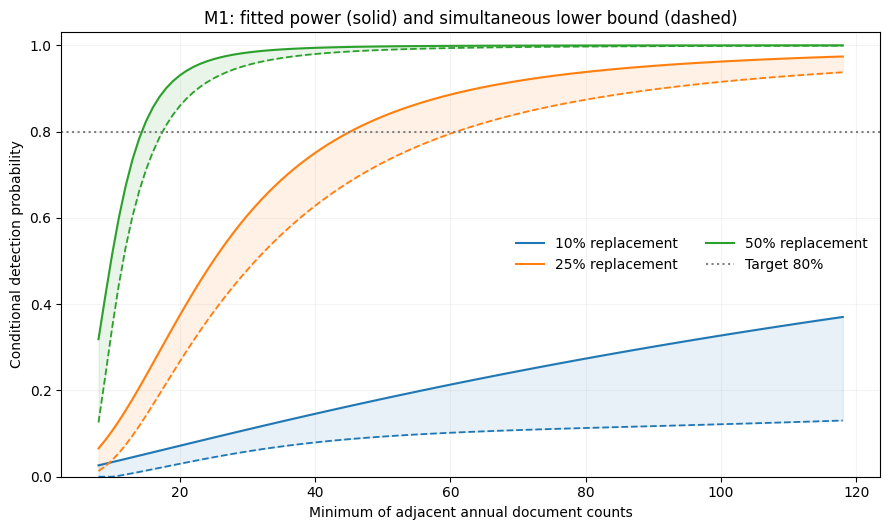

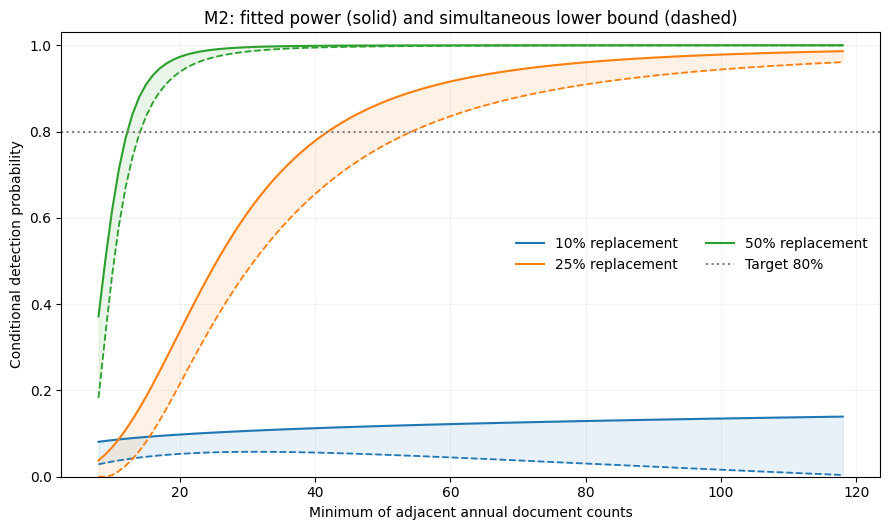

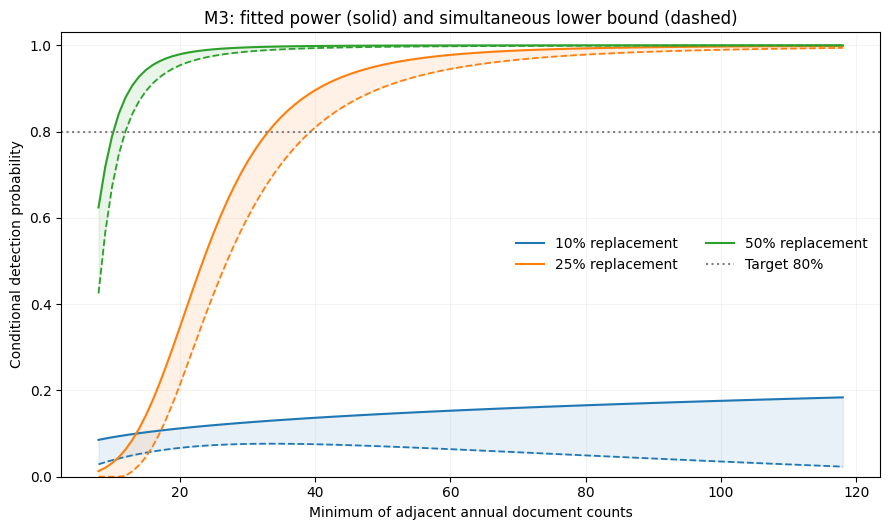

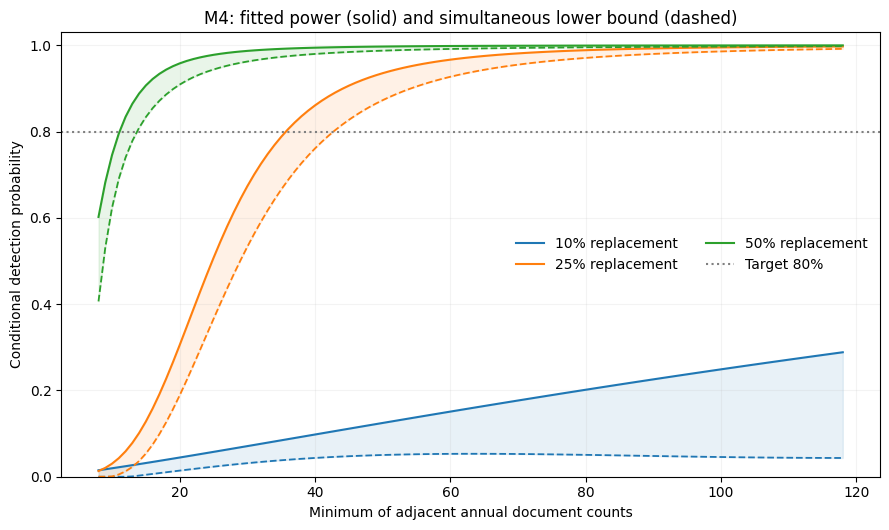

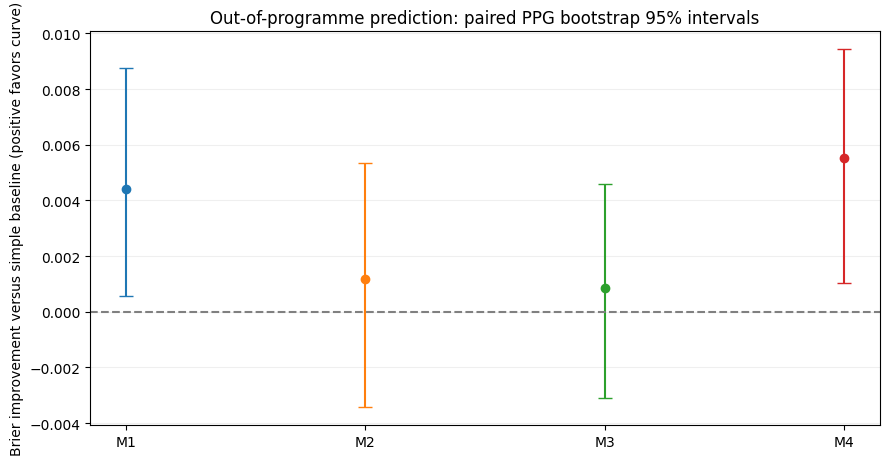

In [ ]:
# 07 — Publication-grade figures (data-derived, vector PDF + PNG)
for model in sorted(bands.model.unique()):
 fig,ax=plt.subplots(figsize=(9,5.4))
 for d in [.1,.25,.5]:
  dd=bands[(bands.model==model)&np.isclose(bands.intensity,d)]
  color_line,=ax.plot(dd.n_effective,dd.power_point,label=f'{d:.0%} replacement')
  ax.plot(dd.n_effective,dd.lower_simultaneous_bootstrap_t,
          color=color_line.get_color(),linewidth=1.3,ls='--')
  ax.fill_between(dd.n_effective.to_numpy(),dd.lower_simultaneous_bootstrap_t.to_numpy(),
                  dd.power_point.to_numpy(),color=color_line.get_color(),alpha=.10)
 ax.axhline(TARGET,ls=':',color='grey',label='Target 80%')
 ax.set(xlabel='Minimum of adjacent annual document counts',
        ylabel='Conditional detection probability',ylim=(0,1.03),
        title=f'{model}: fitted power (solid) and simultaneous lower bound (dashed)')
 ax.legend(frameon=False,ncol=2);ax.grid(alpha=.14);fig.tight_layout()
 for ext in ['pdf','png']:
  fig.savefig(OUT/f'FIG_01_{model}_SIMULTANEOUS_LOWER.{ext}',dpi=350,bbox_inches='tight')
 plt.show();plt.close(fig)

fig,ax=plt.subplots(figsize=(9,4.7))
for model,g in scoreci[scoreci.metric=='brier_diff'].groupby('model'):
 rr=g.iloc[0];i=int(model[1:])-1
 ax.errorbar(i,rr.mean_improvement_vs_baseline,
  yerr=[[rr.mean_improvement_vs_baseline-rr.low95_cluster_boot],
        [rr.high95_cluster_boot-rr.mean_improvement_vs_baseline]],fmt='o',capsize=5,label=model)
ax.axhline(0,color='grey',ls='--');ax.set_xticks(range(4),['M1','M2','M3','M4'])
ax.set(ylabel='Brier improvement versus simple baseline (positive favors curve)',
 title='Out-of-programme prediction: paired PPG bootstrap 95% intervals')
ax.grid(axis='y',alpha=.2);fig.tight_layout()
for ext in ['pdf','png']:fig.savefig(OUT/f'FIG_02_GROUPED_CV_SCORE_IMPROVEMENT.{ext}',dpi=350,bbox_inches='tight')
plt.show();plt.close(fig)

In [ ]:
# 08 — Scientific readiness gates, manifests, readable handoff
checks=[
 ('Frozen original SHA256 identities verified',True),
 ('Estimator reconstructed from independently verified frozen outcomes',True),
 ('Max-deviation one-sided approximate simultaneous envelope computed',len(summary)==12),
 ('Threshold crossing restricted to observed size support',bool((summary.n_max<=118).all())),
 ('Grouped CV paired cluster bootstrap finished',len(scoreci)==8),
 ('Temporal predictions evaluated without refitting',len(transci)==16),
 ('External historical truth established',False),
 ('Distribution-free finite-sample simultaneous coverage proven',False),
 ('Original JOI methodological innovation independently established',False),
 ('Independent paper non-overlap with submitted LAB98 established',False),
 ('Previously exposed 2022-2024 treated as pristine',False)]
gates=pd.DataFrame(checks,columns=['gate','passed'])
gates.to_csv(OUT/'08_METHOD_AND_EDITORIAL_GATES.csv',index=False)
inputs={label:{'path':str(p),'sha256':h} for label,(p,h) in FILES.items()}
inputs.update({name:{'path':str(P101/name),'sha256':sha256(P101/name)} for name in INPUT101})
(OUT/'00_FROZEN_INPUTS_MANIFEST.json').write_text(json.dumps(inputs,indent=2))
report={
 'lab':'JOI-102','created_utc':datetime.now(timezone.utc).isoformat(),
 'status':'METHOD_SENSITIVITY_COMPLETED_NOT_SUBMISSION_APPROVAL',
 'purpose':'approximately simultaneous lower power envelopes; paired score uncertainty; decision-level comparison',
 'target_power':TARGET,'nominal_alpha':ALPHA,'bootstrap_B':B,
 'n_selected_pairs':352,'n_models':4,
 'threshold_summary':summary.where(pd.notnull(summary),None).to_dict('records'),
 'cv_score_interval':scoreci.to_dict('records'),
 'temporal_score_interval':transci.to_dict('records'),
 'fundamental_caveats':[
   'Bootstrap max-t band is asymptotic/approximate conditional on logistic specification, not distribution-free or guaranteed 95% coverage',
   'Inversion over n searches a curve, making pointwise intervals insufficient',
   'Selected intervention documents are not verified historical epistemic transformations',
   'Interventions 10/25/50% are experimental, n80 is not an ex ante prediction',
   'Four encoders depend on same scientific source records',
   '2022-2024 was previously exposed to prior analysis',
   'Material overlap with submitted LAB98 must be explicitly evaluated before a second manuscript',
   'No joint permutation null is reconstructed from marginal p values']}
(OUT/'09_FINAL_HANDOFF.json').write_text(json.dumps(report,ensure_ascii=False,indent=2,default=str))
manifest=[]
for p in sorted(OUT.iterdir()):
 if p.is_file():manifest.append({'file':p.name,'bytes':p.stat().st_size,'sha256':sha256(p)})
(OUT/'10_OUTPUT_MANIFEST_SHA256.json').write_text(json.dumps(manifest,indent=2))
print('LAB-JOI 102 COMPLETED:',OUT)
print('Simultaneous thresholds:');display(summary[['model','intensity','n80_point','n80_pointwise_lower','n80_simultaneous_lower','status']])
print('Grouped CV score gain and uncertainty:');display(scoreci)
print('Temporal transfer and uncertainty:');display(transci)
print('Final handoff:',OUT/'09_FINAL_HANDOFF.json')

LAB-JOI 102 COMPLETED: /content/drive/MyDrive/CAPES_Epistemic_Change/102JOI_LAB04_SIMULTANEOUS_RESOLUTION_VALIDATION_V1
Simultaneous thresholds:


,model,intensity,n80_point,n80_pointwise_lower,n80_simultaneous_lower,status
0,M1,0.10,NaN,NaN,NaN,NOT_IDENTIFIED
1,M1,0.25,46.0,57.0,61.0,SIMULTANEOUS_LOWER_CROSSES
2,M1,0.50,15.0,17.0,18.0,SIMULTANEOUS_LOWER_CROSSES
3,M2,0.10,NaN,NaN,NaN,NOT_IDENTIFIED
4,M2,0.25,42.0,52.0,55.0,SIMULTANEOUS_LOWER_CROSSES
5,M2,0.50,13.0,14.0,15.0,SIMULTANEOUS_LOWER_CROSSES
6,M3,0.10,NaN,NaN,NaN,NOT_IDENTIFIED
7,M3,0.25,34.0,38.0,40.0,SIMULTANEOUS_LOWER_CROSSES
8,M3,0.50,11.0,12.0,12.0,SIMULTANEOUS_LOWER_CROSSES
9,M4,0.10,NaN,NaN,NaN,NOT_IDENTIFIED


Grouped CV score gain and uncertainty:


,model,metric,mean_improvement_vs_baseline,low95_cluster_boot,high95_cluster_boot,n_rows,n_ppg,bootstrap_pr_improvement_positive
0,M1,brier_diff,0.004421,0.000586,0.008758,576,181,0.9875
1,M1,logloss_diff,0.015563,0.003787,0.027808,576,181,1.0000
2,M2,brier_diff,0.001182,-0.003433,0.005350,576,181,0.7075
3,M2,logloss_diff,0.003449,-0.010796,0.015919,576,181,0.6975
4,M3,brier_diff,0.000857,-0.003081,0.004604,576,181,0.6950
5,M3,logloss_diff,0.004522,-0.007096,0.015811,576,181,0.7900
6,M4,brier_diff,0.005518,0.001038,0.009434,576,181,0.9975
7,M4,logloss_diff,0.020052,0.003239,0.036009,576,181,0.9950


Temporal transfer and uncertainty:


,model,phase,metric,n_rows,n_ppg,mean_improvement_vs_baseline,low95_cluster_boot,high95_cluster_boot
0,M1,REPLICATION_2020_2021,brier_diff,192,64,0.003649,-0.002665,0.009626
1,M1,REPLICATION_2020_2021,logloss_diff,192,64,0.012075,-0.008862,0.029950
2,M1,REPLICATION_EXPOSED_2022_2024,brier_diff,288,95,0.006287,0.001541,0.010966
3,M1,REPLICATION_EXPOSED_2022_2024,logloss_diff,288,95,0.018164,0.004060,0.030390
4,M2,REPLICATION_2020_2021,brier_diff,192,64,0.004193,-0.004081,0.011799
5,M2,REPLICATION_2020_2021,logloss_diff,192,64,0.011176,-0.010642,0.035568
6,M2,REPLICATION_EXPOSED_2022_2024,brier_diff,288,95,0.004846,-0.000228,0.009471
7,M2,REPLICATION_EXPOSED_2022_2024,logloss_diff,288,95,0.017491,0.004819,0.029171
8,M3,REPLICATION_2020_2021,brier_diff,192,64,0.004566,-0.002340,0.011542
9,M3,REPLICATION_2020_2021,logloss_diff,192,64,0.013403,-0.017350,0.047655


Final handoff: /content/drive/MyDrive/CAPES_Epistemic_Change/102JOI_LAB04_SIMULTANEOUS_RESOLUTION_VALIDATION_V1/09_FINAL_HANDOFF.json
